# Objectifs d'apprentissage – Semaine 10

À l'issue de cette semaine, l'étudiant sera capable de :

- **Comprendre** les différentes structures d'implémentation des filtres RIF et RII.
- **Implémenter** un filtre RIF sous forme directe et en cascade.
- **Implémenter** un filtre RII sous forme directe I, directe II, cascade et parallèle.
- **Analyser** l'influence de la structure sur les performances (stabilité, bruit de calcul).
- **Évaluer** le retard de groupe et la phase d'un filtre.
- **Simuler** les effets de la quantification en virgule fixe sur un filtre numérique.
- **Comparer** les filtres RIF et RII en termes de complexité, phase et stabilité.
- **Utiliser** Python pour l'implémentation et l'analyse de filtres numériques.

# 1. Rappels théoriques

## 1.1 Structures pour les filtres RIF

Un filtre RIF (FIR) est défini par l'équation aux différences :
$$ y[n] = \sum_{k=0}^{M} b_k \, x[n-k] $$

### Structure directe (transversale)
C'est l'implémentation directe de la convolution. Elle est simple et stable, mais peut nécessiter beaucoup de multiplications si l'ordre est élevé.

### Structure en cascade
On factorise la fonction de transfert en sections du second ordre (SOS) :
$$ H(z) = \prod_{k} H_k(z) $$
avec $H_k(z) = b_{0k} + b_{1k} z^{-1} + b_{2k} z^{-2}$.
Cela permet de réduire les effets de quantification et d'implémenter des filtres de grande longueur.

### Structure pour phase linéaire
Si les coefficients sont symétriques, on peut réduire le nombre de multiplications par 2.

## 1.2 Structures pour les filtres RII

Un filtre RII (IIR) est défini par :
$$ \sum_{k=0}^{N} a_k \, y[n-k] = \sum_{k=0}^{M} b_k \, x[n-k] $$
avec $a_0 = 1$.

### Forme directe I
Sépare les parties feedforward (numérateur) et feedback (dénominateur).

### Forme directe II
Réduction du nombre de registres en partageant les retards. Plus économe en mémoire.

### Forme en cascade
Factorisation en sections du second ordre (biquad) : $H(z) = \prod H_k(z)$.
Chaque section est stable si ses pôles sont à l'intérieur du cercle unité.
Cette structure minimise les effets de la quantification et est la plus utilisée en pratique.

### Forme parallèle
Décomposition en fractions partielles : $H(z) = K + \sum \frac{r_k}{1 - p_k z^{-1}}$.
Utilisée parfois pour des filtres à pôles réels.

## 1.3 Retard de groupe
Le retard de groupe $\tau_g(\omega)$ est défini par :
$$ \tau_g(\omega) = -\frac{d}{d\omega} \arg H(e^{j\omega}) $$
Il mesure la distorsion de phase. Pour un filtre à phase linéaire, $\tau_g$ est constant.

## 1.4 Effets de la quantification
En implémentation réelle (processeur DSP, FPGA), les coefficients et les calculs sont quantifiés. Cela peut entraîner :
- Erreurs de troncature/arrondi.
- Bruit de quantification en sortie.
- Oscillations (limit cycles) pour les filtres RII.

---

# 2. Démonstrations Python

## 2.1 Implémentation d'un filtre RIF – Structure directe

Nous allons implémenter un filtre RIF passe-bas en utilisant la convolution directe et comparer avec `lfilter`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import fft, fftfreq

print("Bibliothèques chargées.")

Bibliothèques chargées.


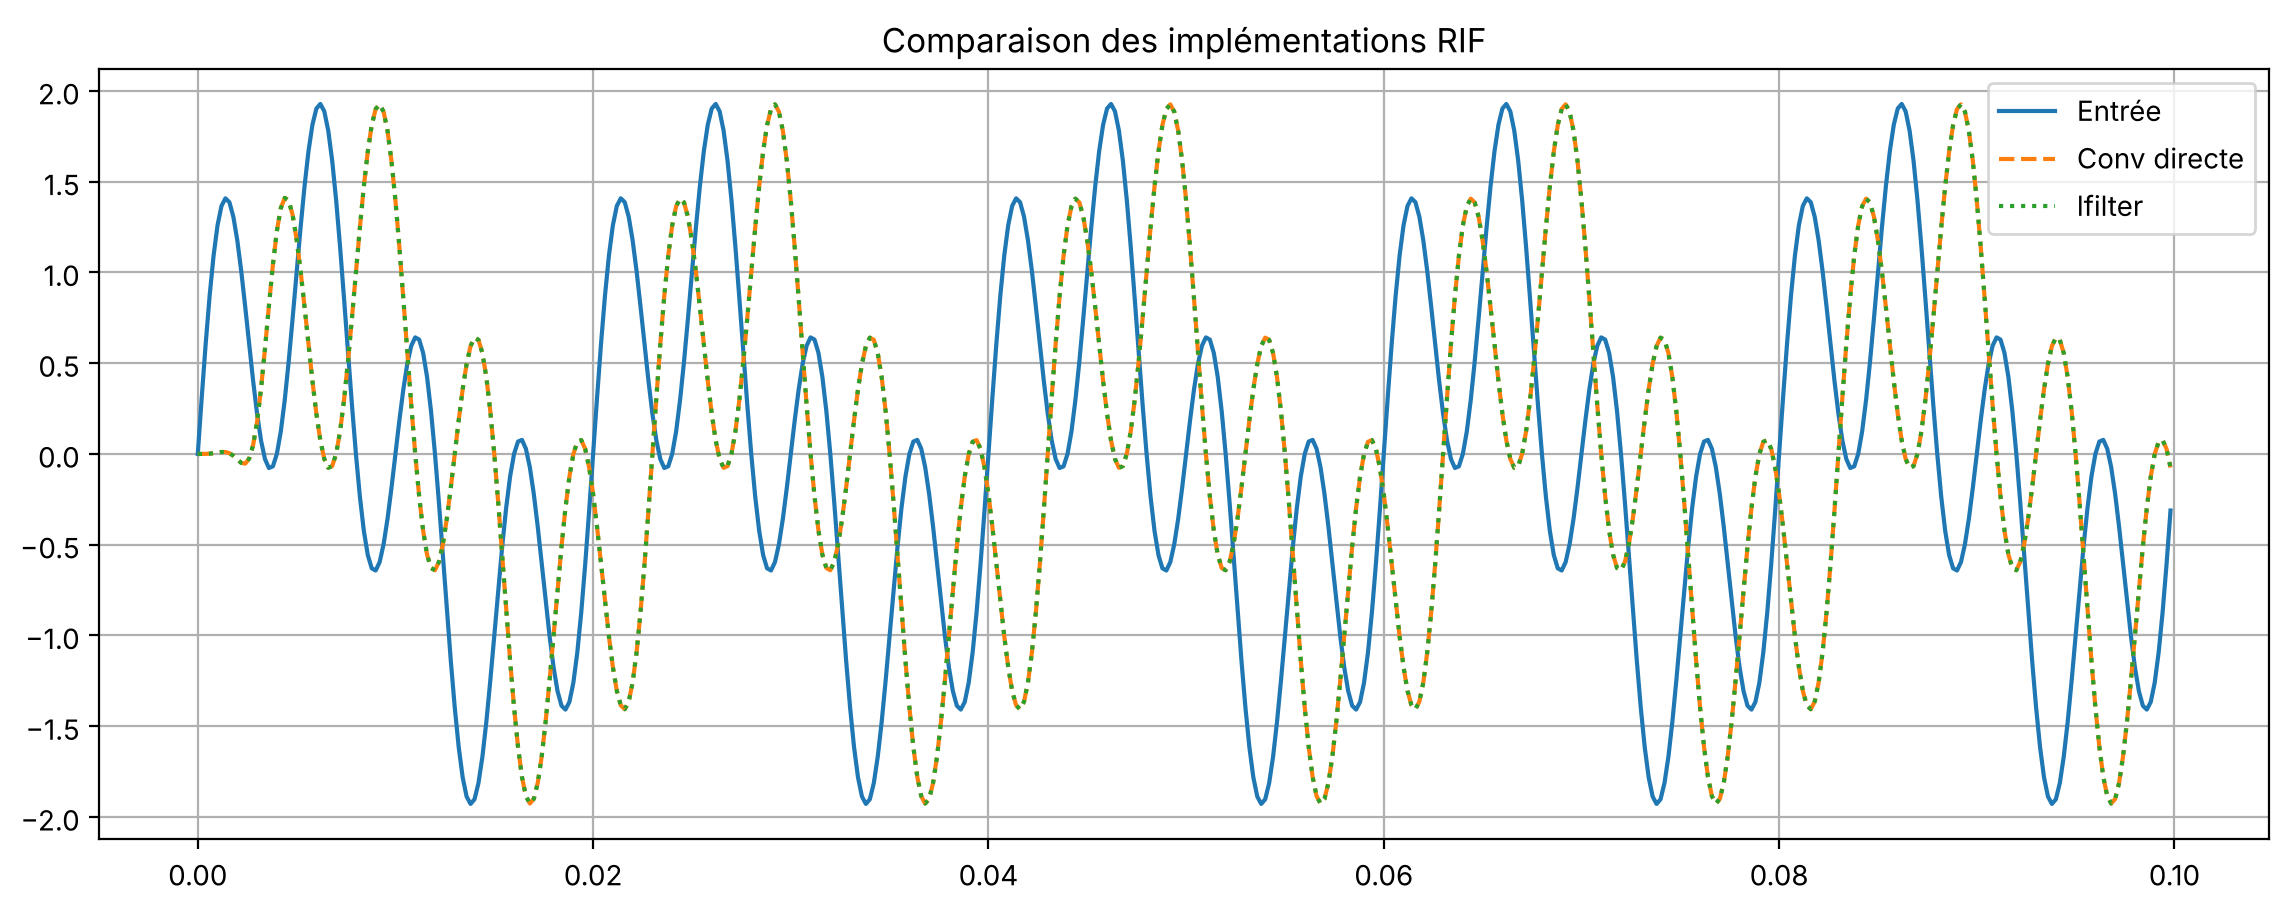

Erreur max entre les deux : 0.0


In [2]:
# Conception d'un filtre RIF passe-bas
fs = 1000
fc = 100
N = 31  # ordre 30
b = signal.firwin(N, fc, fs=fs, window='hamming')

# Implémentation directe par convolution
def fir_filter(x, b):
    y = np.convolve(x, b, mode='full')
    return y[:len(x)]  # on tronque pour garder la même longueur

# Signal test
t = np.linspace(0, 0.1, 500, endpoint=False)
x = np.sin(2*np.pi*50*t) + np.sin(2*np.pi*200*t)

y_conv = fir_filter(x, b)
y_lfilter = signal.lfilter(b, 1, x)

plt.figure(figsize=(14, 5))
plt.plot(t, x, label='Entrée')
plt.plot(t, y_conv, '--', label='Conv directe')
plt.plot(t, y_lfilter, ':', label='lfilter')
plt.legend()
plt.grid()
plt.title('Comparaison des implémentations RIF')
plt.show()
print("Erreur max entre les deux :", np.max(np.abs(y_conv - y_lfilter)))

## 2.2 Structure en cascade pour RIF

Décomposons un filtre RIF en sections du second ordre.

Nombre de sections : 15
[[ 1.20142638e-03 -3.50782491e-03  2.66704843e-03  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00 -7.60763806e-01  1.13993205e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  8.16718191e-01  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00 -4.45897340e-01  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  1.90247028e+00  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  4.18723996e-01  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00 -1.09876196e+00  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  1.48805025e+00  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  1.98908417e+00  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  1.17819278e+00  1.00000000e+00  1.00000000e+00
 

/usr/local/lib/python3.12/dist-packages/scipy/signal/_filter_design.py:1234: BadCoefficients: Badly conditioned filter coefficients (numerator): the results may be meaningless
  b, a = normalize(b, a)


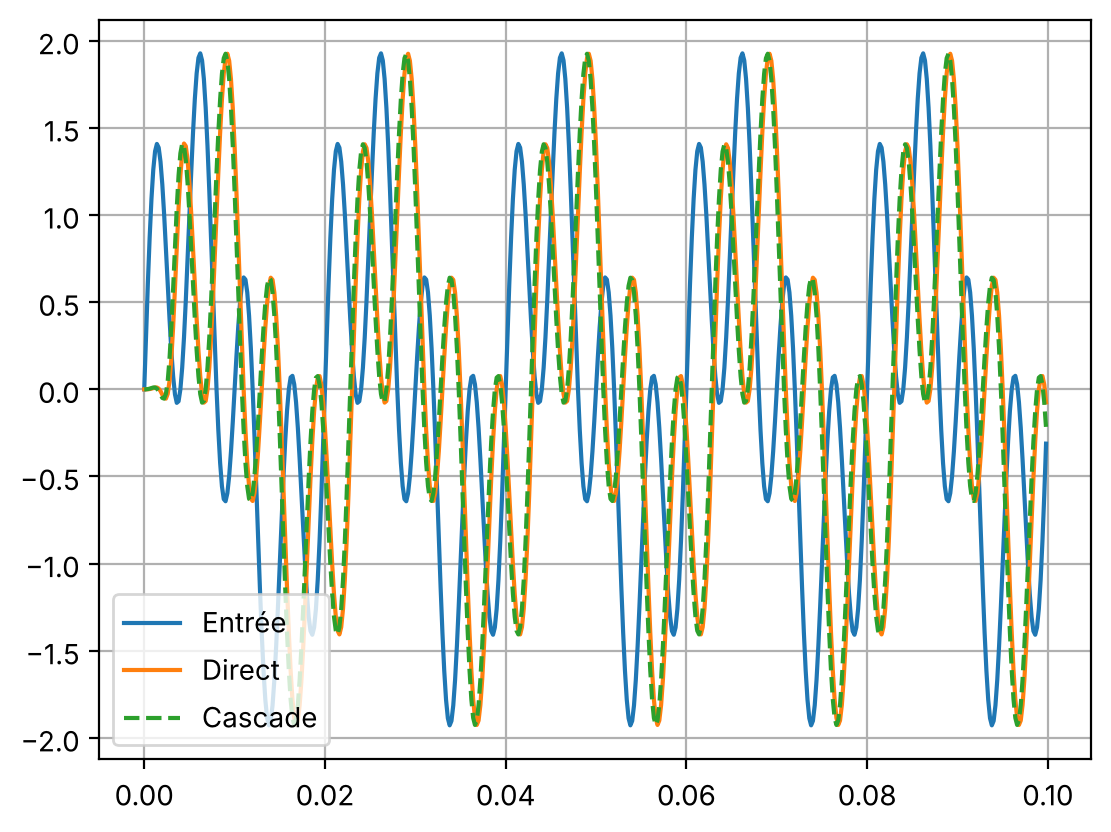

Erreur max : 0.31101699893362933


In [3]:
# Utilisation de scipy.signal.tf2sos pour obtenir les sections
sos = signal.tf2sos(b, 1)
print(f"Nombre de sections : {len(sos)}")
print(sos)

# Implémentation en cascade
def fir_sos_filter(x, sos):
    y = x.copy()
    for section in sos:
        b_section = section[:3]
        # a_section = section[3:]  # pour RIF, a = [1, 0, 0] car section purement feedforward
        y = signal.lfilter(b_section, [1], y)
    return y

y_cascade = fir_sos_filter(x, sos)

plt.plot(t, x, label='Entrée')
plt.plot(t, y_lfilter, label='Direct')
plt.plot(t, y_cascade, '--', label='Cascade')
plt.legend()
plt.grid()
plt.show()
print("Erreur max :", np.max(np.abs(y_lfilter - y_cascade)))

## 2.3 Structures pour les filtres RII

Nous allons concevoir un filtre RII (Butterworth) et l'implémenter dans différentes structures.

Nombre de sections : 2


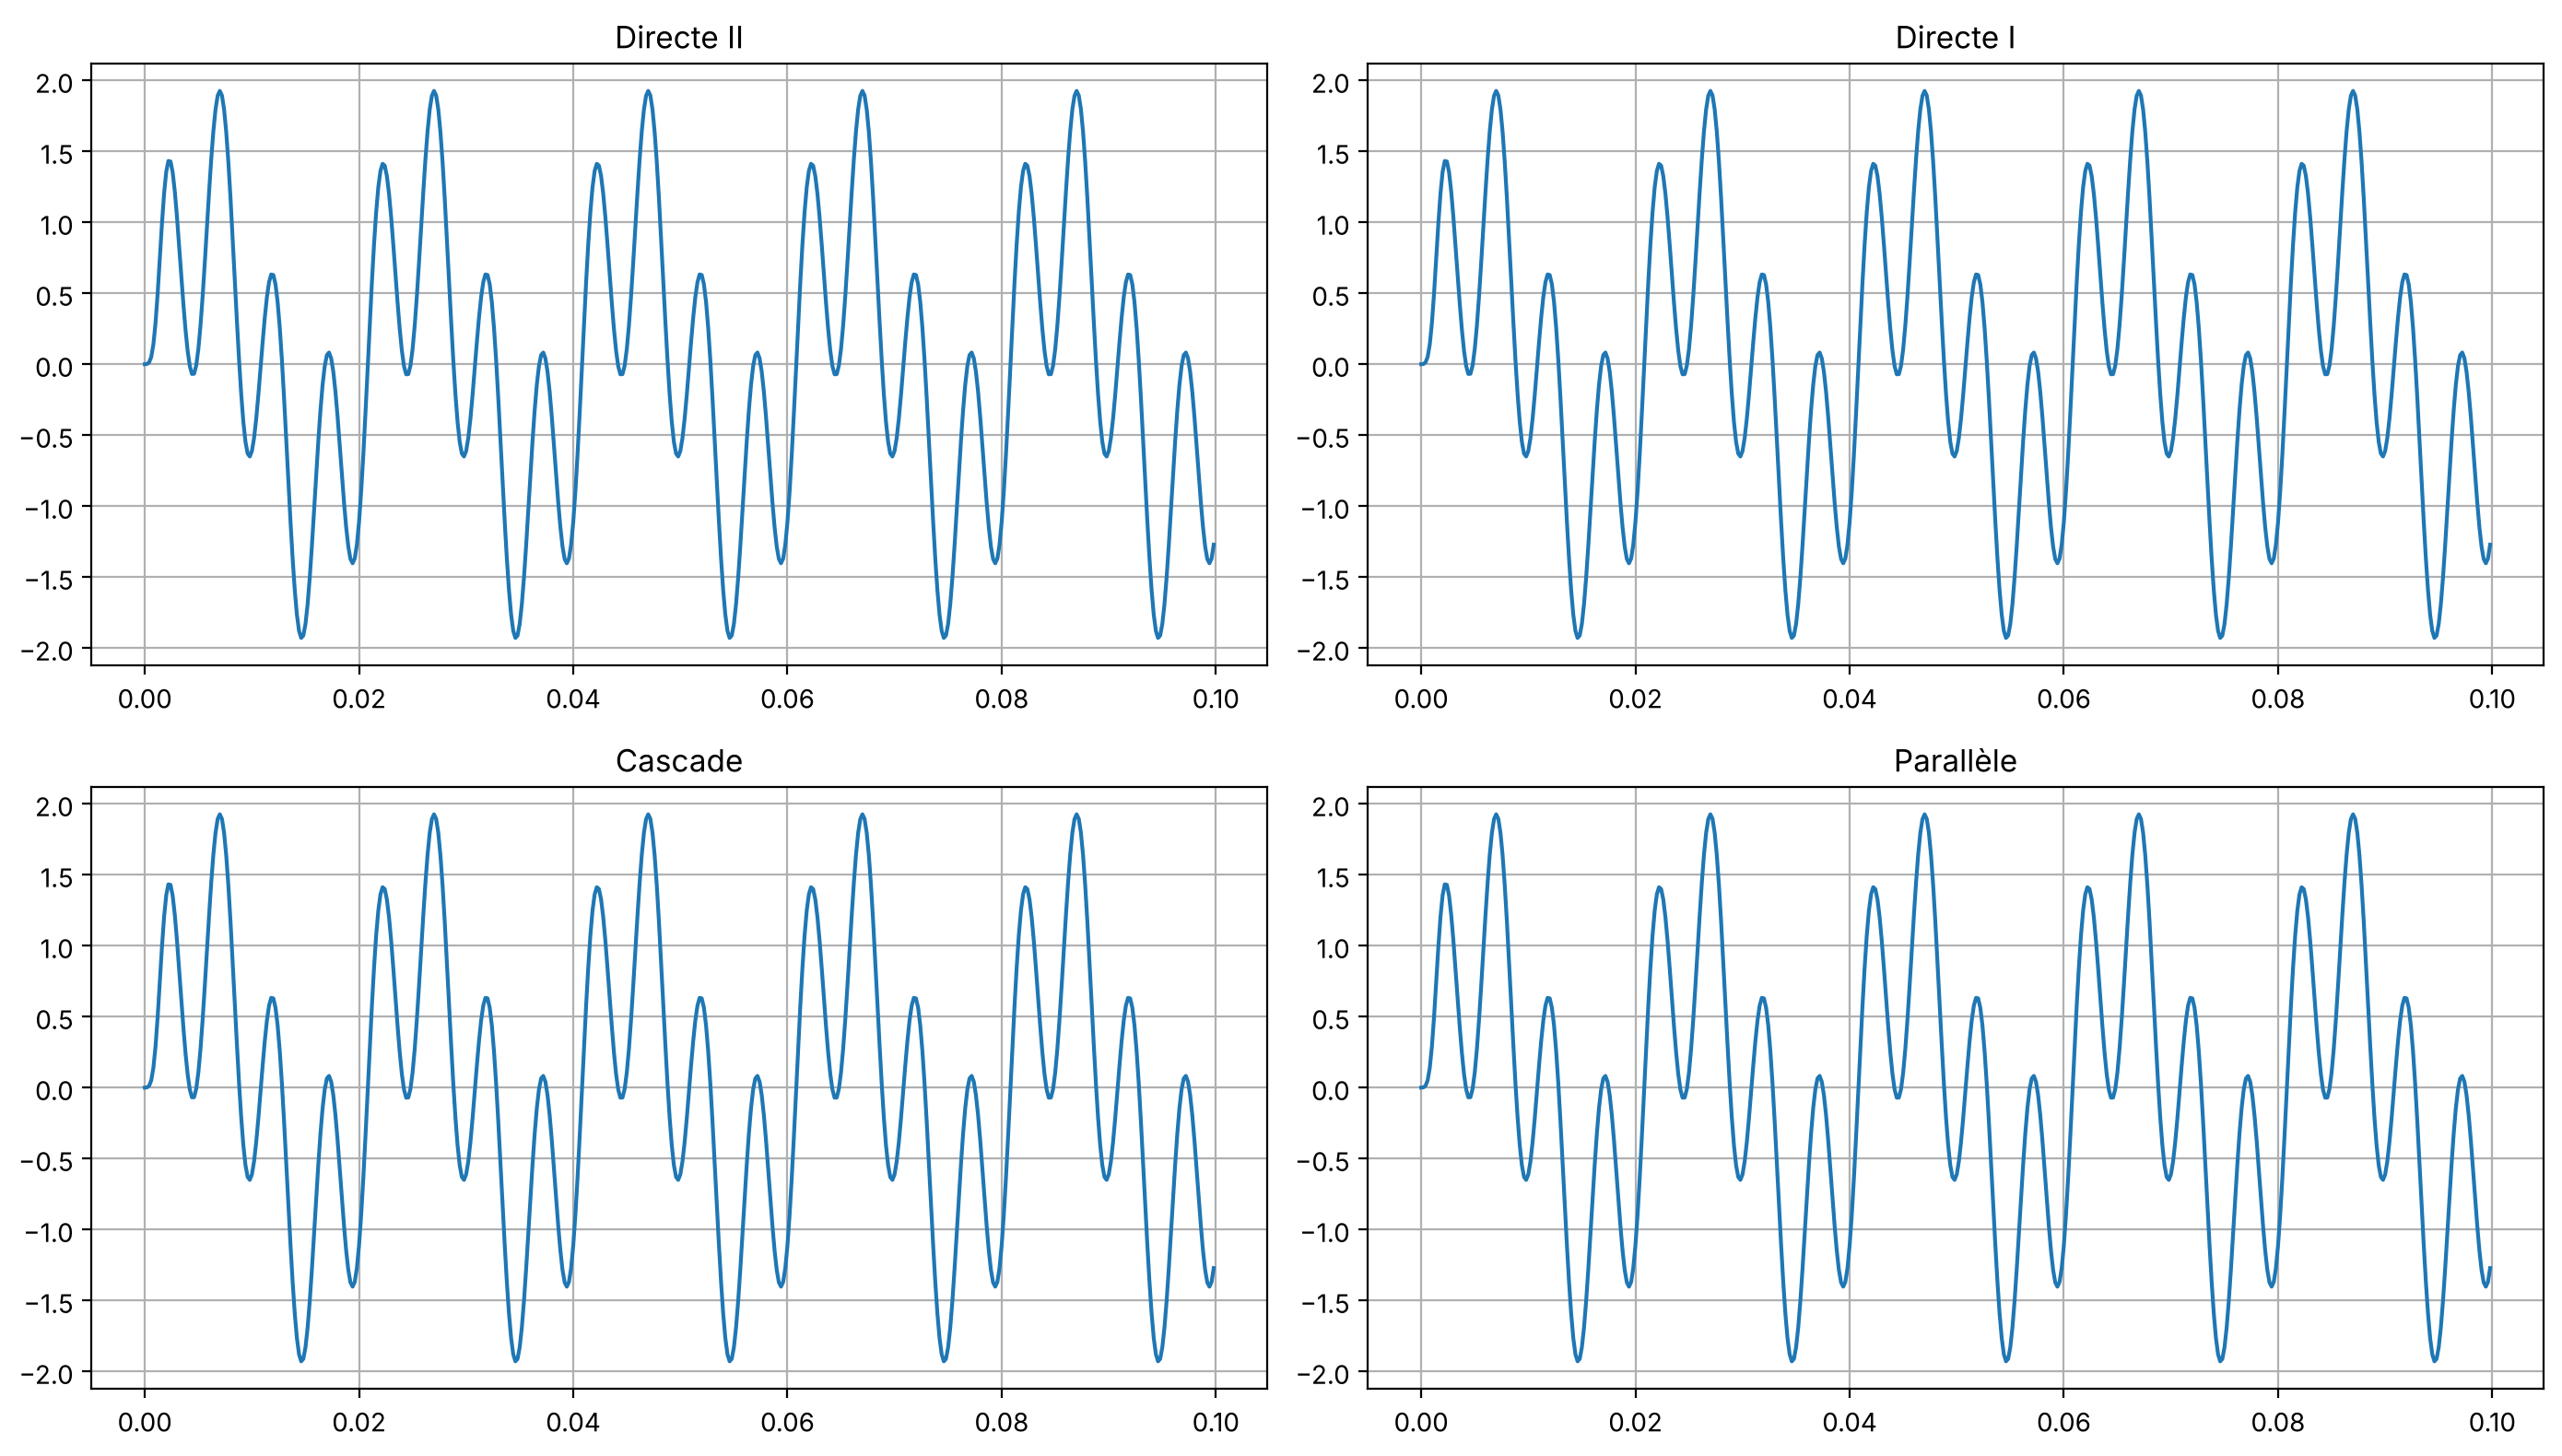

Erreur max Directe I vs Directe II: 5.773159728050814e-15
Erreur max Cascade vs Directe II: 7.327471962526033e-15
Erreur max Parallèle vs Directe II: 2.0872192862952943e-14


In [4]:
# Conception d'un filtre RII passe-bas Butterworth ordre 4
order = 4
b_iir, a_iir = signal.butter(order, fc, fs=fs, btype='low')

# Forme directe II (via lfilter déjà)
y_direct2 = signal.lfilter(b_iir, a_iir, x)

# Forme directe I (implémentation manuelle)
def iir_direct1(x, b_iir, a_iir):
    # On suppose a_iir[0]=1
    N = len(x)
    M = len(b_iir) - 1
    N_a = len(a_iir) - 1
    y = np.zeros(N)
    x_buf = np.zeros(M+1)
    y_buf = np.zeros(N_a+1)
    for n in range(N):
        # Mise à jour des buffers
        x_buf[1:] = x_buf[:-1]
        x_buf[0] = x[n]
        y_buf[1:] = y_buf[:-1]
        # Calcul
        y[n] = np.dot(b_iir, x_buf) - np.dot(a_iir[1:], y_buf[1:])
        y_buf[0] = y[n]
    return y

y_direct1 = iir_direct1(x, b_iir, a_iir)

# Forme en cascade (sections biquad)
sos_iir = signal.tf2sos(b_iir, a_iir)
print(f"Nombre de sections : {len(sos_iir)}")
def iir_sos_filter(x, sos):
    y = x.copy()
    for section in sos:
        b_section = section[:3]
        a_section = section[3:]
        y = signal.lfilter(b_section, a_section, y)
    return y

y_sos = iir_sos_filter(x, sos_iir)

# Forme parallèle (décomposition en fractions partielles)
r, p, k = signal.residuez(b_iir, a_iir)
# def iir_parallel(x, r, p, k):
#     y = np.zeros_like(x)
#     # Terme direct
#     if len(k) > 0:
#         y += k[0] * x
#     # Chaque fraction
#     for ri, pi in zip(r, p):
#         # H(z) = ri / (1 - pi z^{-1})
#         # Implémentation récursive du premier ordre
#         b_sec = [ri]
#         a_sec = [1, -pi]
#         y += signal.lfilter(b_sec, a_sec, x)
#     return y

def iir_parallel(x, r, p, k):
    dtype = np.result_type(x, r, p, k)
    y = np.zeros_like(x, dtype=dtype)

    # Terme direct
    if len(k) > 0:
        y += k[0] * x

    # Somme des fractions du filtre
    for ri, pi in zip(r, p):
        y += signal.lfilter([ri], [1, -pi], x)

    # Le filtre étant réel, les parties imaginaires résiduelles
    # dues aux arrondis numériques doivent être négligeables.
    return np.real_if_close(y)

y_parallel = iir_parallel(x, r, p, k)

# Comparaison
plt.figure(figsize=(14, 8))
plt.subplot(2, 2, 1)
plt.plot(t, y_direct2, label='Directe II')
plt.title('Directe II')
plt.grid()
plt.subplot(2, 2, 2)
plt.plot(t, y_direct1, label='Directe I')
plt.title('Directe I')
plt.grid()
plt.subplot(2, 2, 3)
plt.plot(t, y_sos, label='Cascade')
plt.title('Cascade')
plt.grid()
plt.subplot(2, 2, 4)
plt.plot(t, y_parallel, label='Parallèle')
plt.title('Parallèle')
plt.grid()
plt.tight_layout()
plt.show()

# Vérification de l'erreur
print("Erreur max Directe I vs Directe II:", np.max(np.abs(y_direct1 - y_direct2)))
print("Erreur max Cascade vs Directe II:", np.max(np.abs(y_sos - y_direct2)))
print("Erreur max Parallèle vs Directe II:", np.max(np.abs(y_parallel - y_direct2)))


## 2.4 Analyse du retard de groupe

Calculons le retard de groupe pour un filtre RIF (phase linéaire) et un filtre RII.

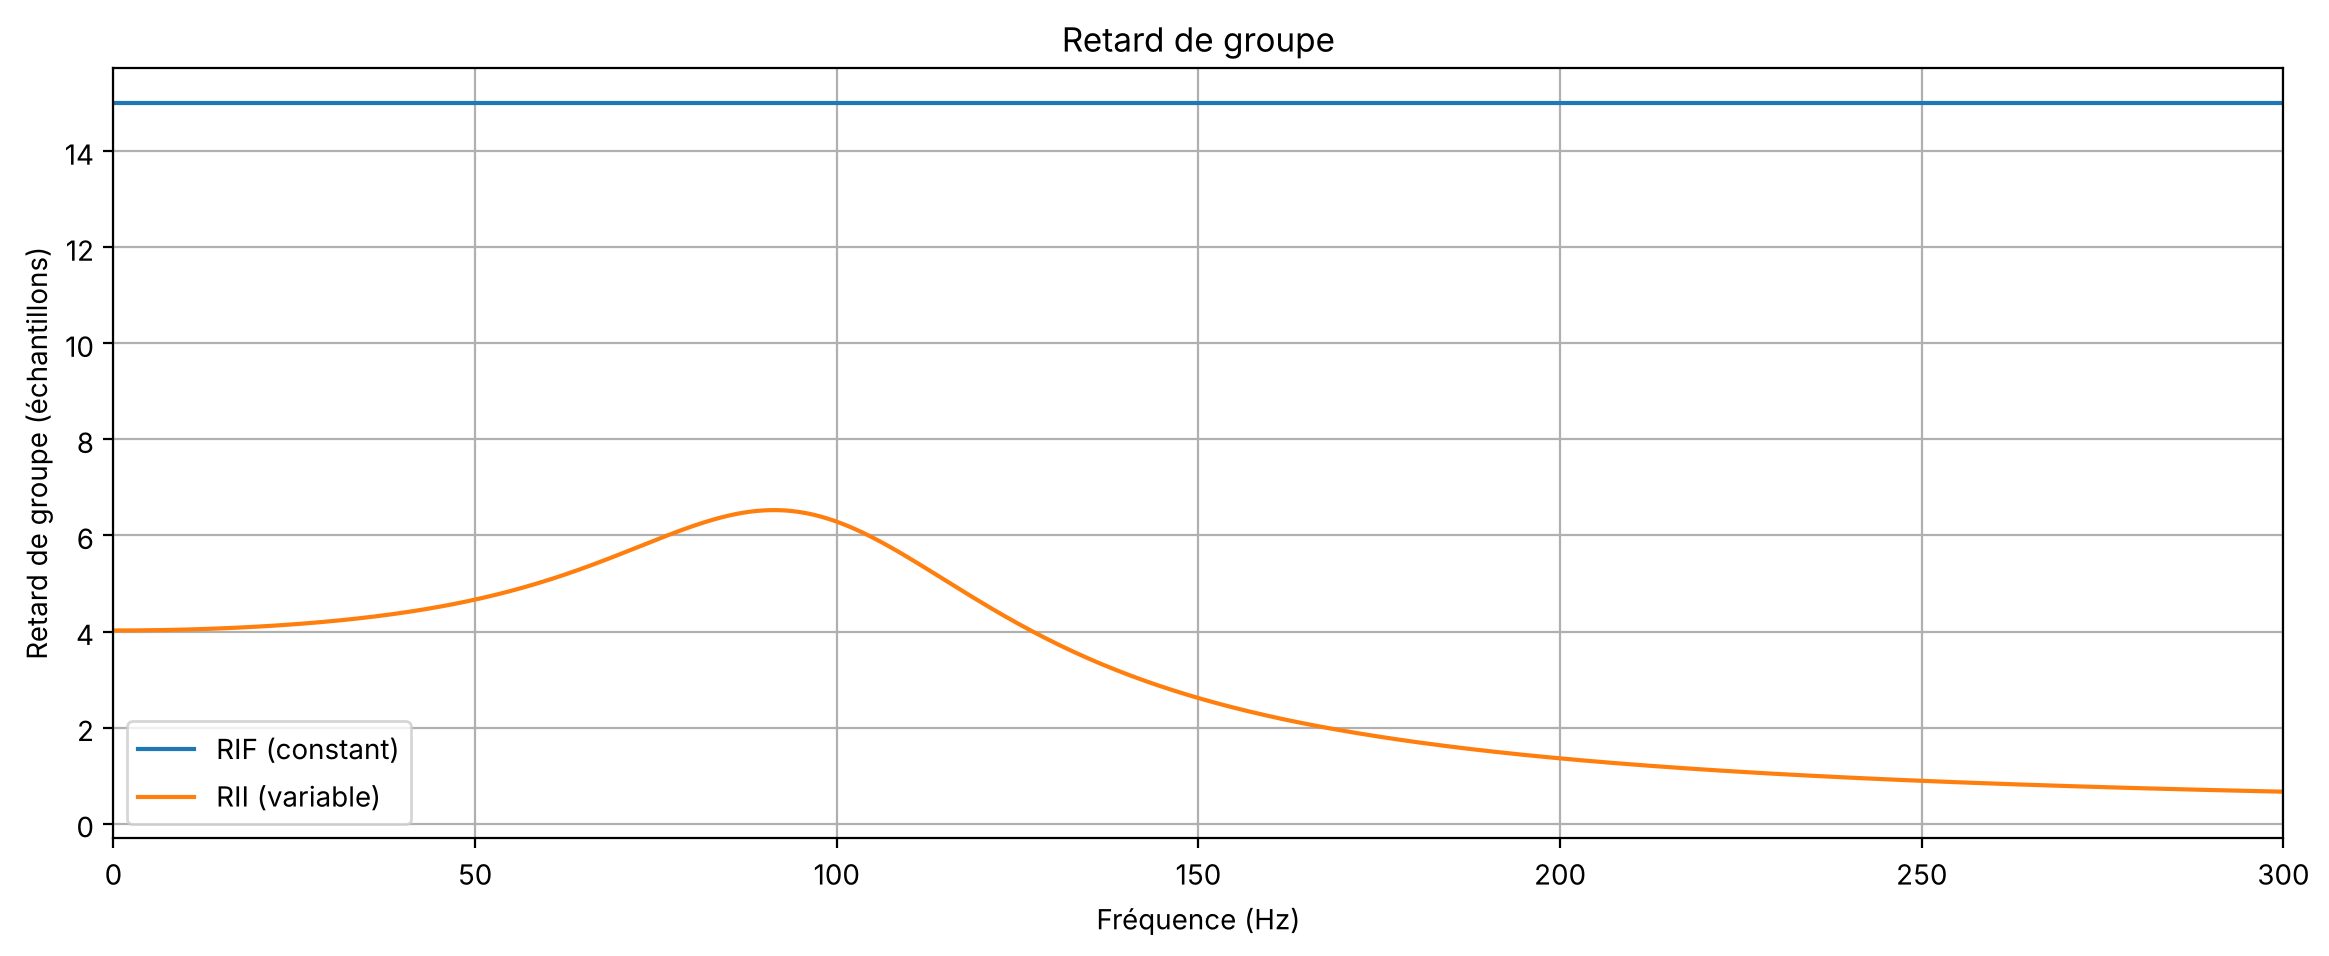

Retard de groupe du RIF (constant) : 15.00 échantillons
Cela correspond à (N-1)/2 = 15 échantillons pour un RIF symétrique d'ordre 30.


In [5]:
from scipy.signal import group_delay

# RIF
w, gd_fir = group_delay((b, 1), w=1024)
# RII
w, gd_iir = group_delay((b_iir, a_iir), w=1024)

freqs = w * fs / (2*np.pi)

plt.figure(figsize=(14, 5))
plt.plot(freqs, gd_fir, label='RIF (constant)')
plt.plot(freqs, gd_iir, label='RII (variable)')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Retard de groupe (échantillons)')
plt.xlim(0, 300)
plt.legend()
plt.grid()
plt.title('Retard de groupe')
plt.show()

print(f"Retard de groupe du RIF (constant) : {gd_fir[0]:.2f} échantillons")
print("Cela correspond à (N-1)/2 = 15 échantillons pour un RIF symétrique d'ordre 30.")

## 2.5 Simulation des effets de quantification

Simulons un filtre RII en virgule fixe (représentation Q15) pour observer l'impact sur la réponse.

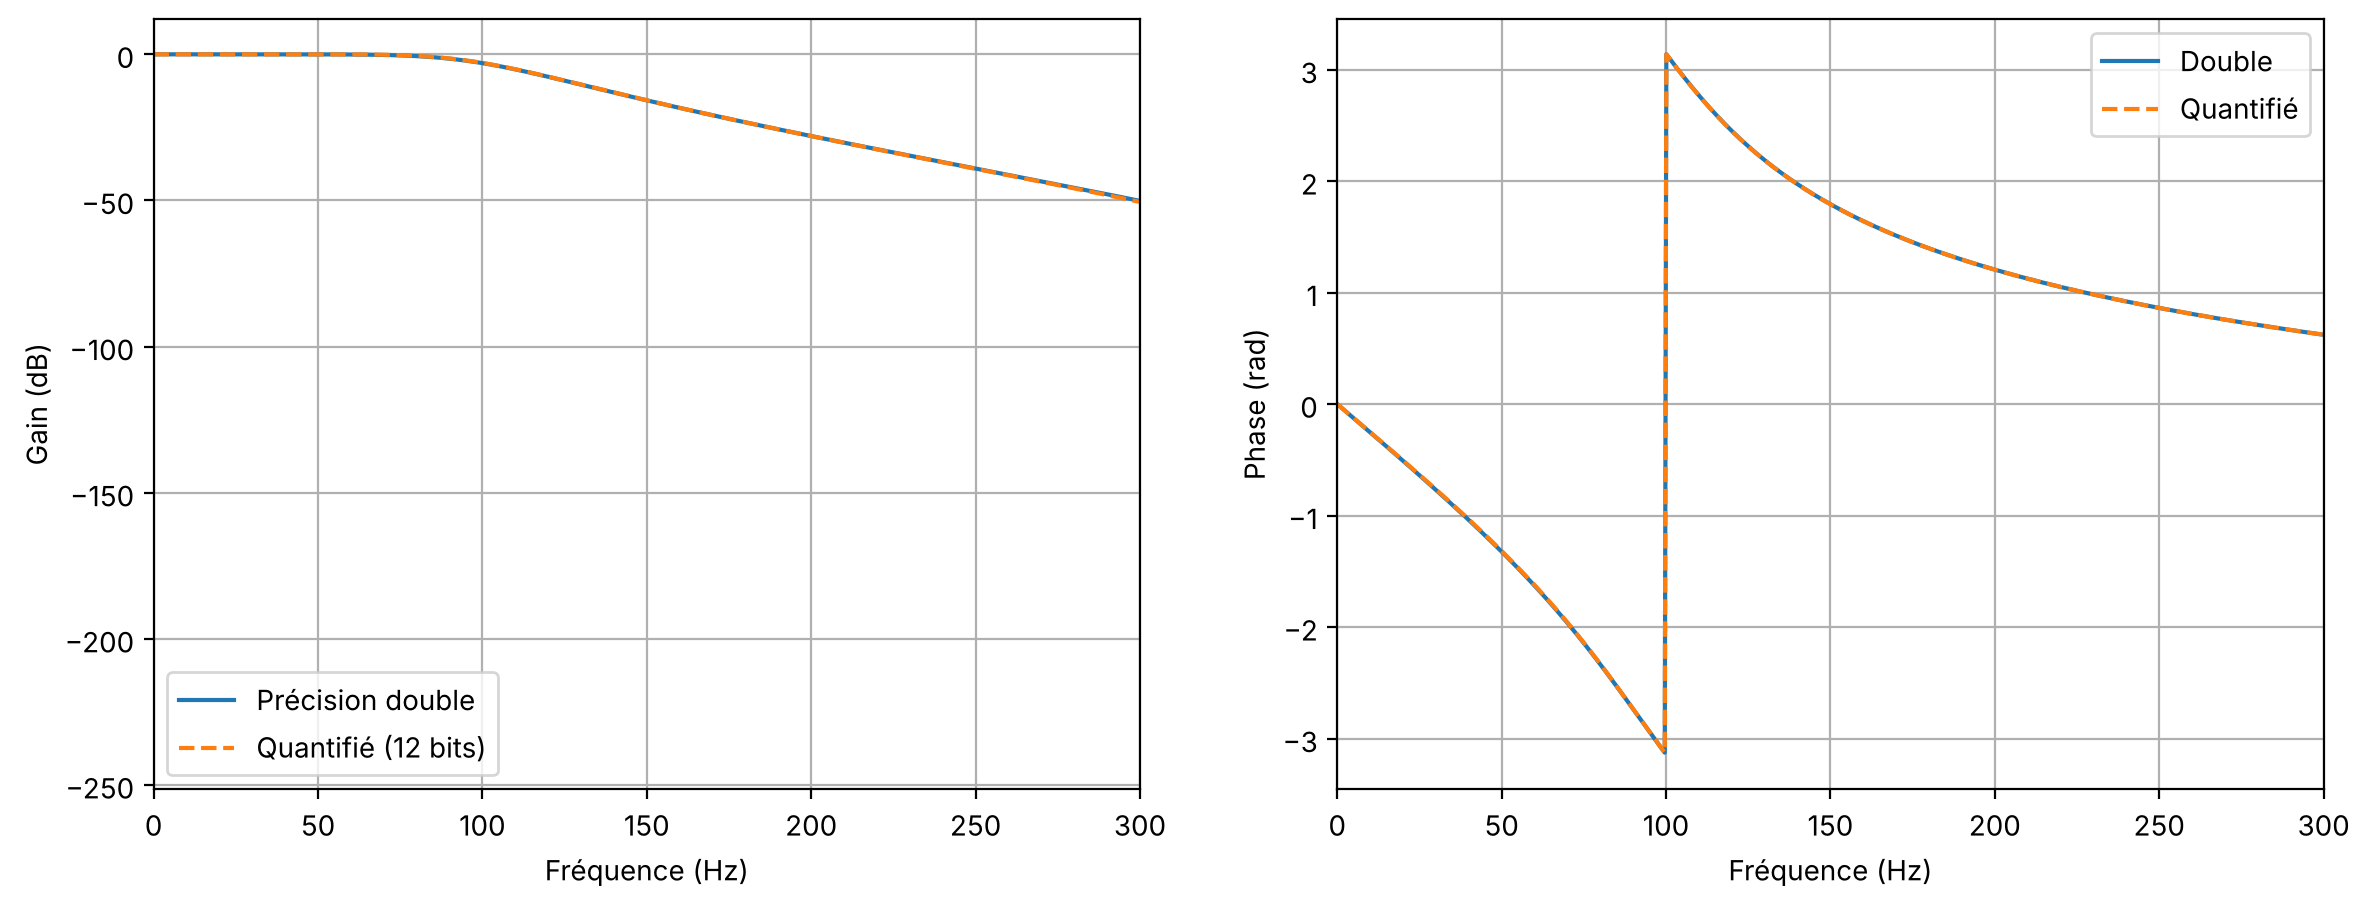

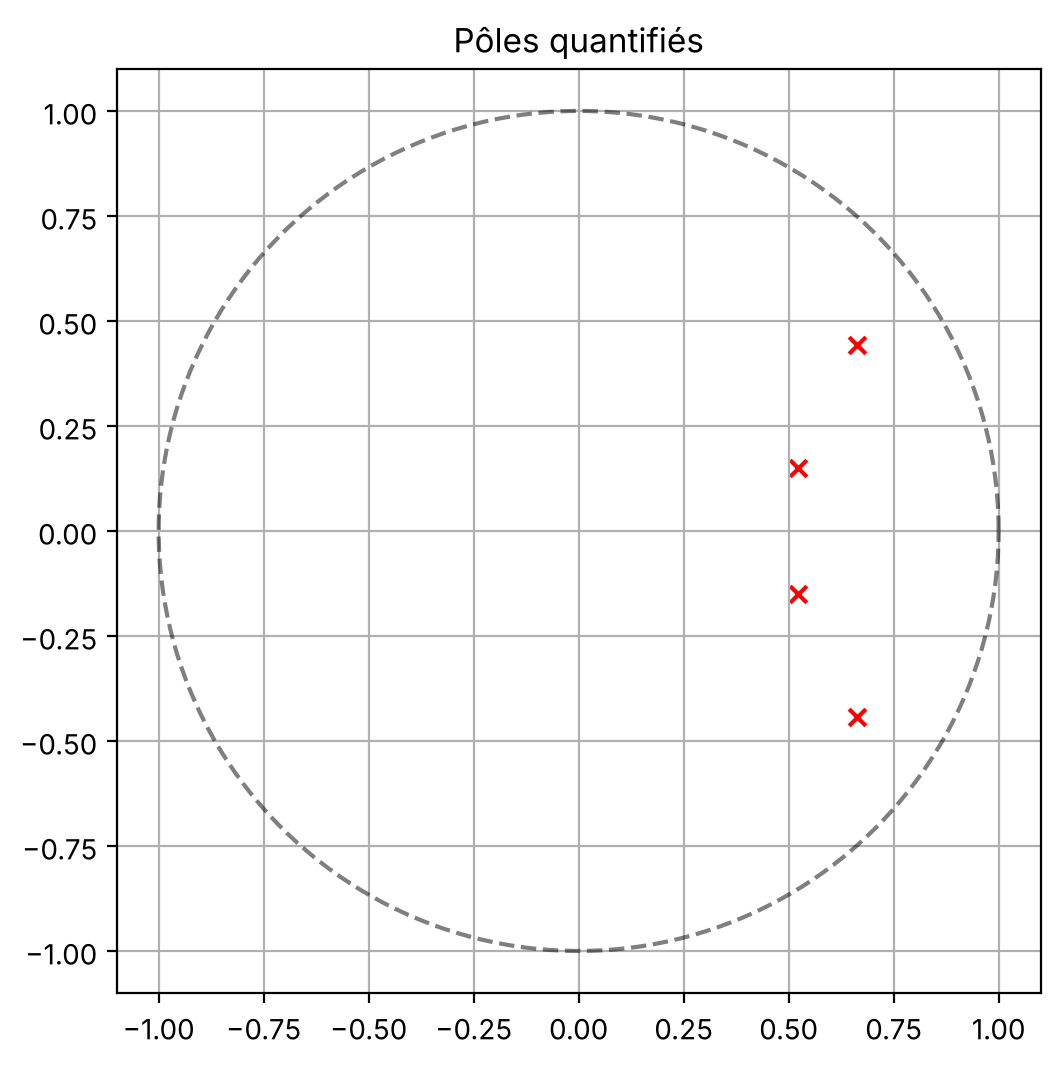

Filtre quantifié stable : True


In [6]:
def quantize_coeffs(coeffs, n_bits=16, scale=1.0):
    """Quantifie des coefficients sur n_bits avec mise à l'échelle."""
    # Qn format : valeurs entre -1 et 1 représentées sur n_bits
    max_val = 2**(n_bits-1) - 1
    coeffs_scaled = coeffs * scale
    coeffs_int = np.round(coeffs_scaled * max_val)
    coeffs_q = coeffs_int / max_val
    return coeffs_q / scale  # remettre à l'échelle

# Quantification des coefficients du RII
b_q = quantize_coeffs(b_iir, n_bits=12)
a_q = quantize_coeffs(a_iir, n_bits=12)

# Réponses fréquentielles
w, H = signal.freqz(b_iir, a_iir, worN=1024)
w, H_q = signal.freqz(b_q, a_q, worN=1024)

freqs = w * fs / (2*np.pi)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(freqs, 20*np.log10(np.abs(H)+1e-12), label='Précision double')
plt.plot(freqs, 20*np.log10(np.abs(H_q)+1e-12), '--', label='Quantifié (12 bits)')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Gain (dB)')
plt.xlim(0, 300)
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(freqs, np.angle(H), label='Double')
plt.plot(freqs, np.angle(H_q), '--', label='Quantifié')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Phase (rad)')
plt.xlim(0, 300)
plt.legend()
plt.grid()
plt.show()

# Pôles quantifiés
zeros, poles, gain = signal.tf2zpk(b_q, a_q)
plt.figure(figsize=(6, 6))
theta = np.linspace(0, 2*np.pi, 200)
plt.plot(np.cos(theta), np.sin(theta), 'k--', alpha=0.5)
plt.scatter(np.real(poles), np.imag(poles), marker='x', color='r')
plt.gca().set_aspect('equal')
plt.title('Pôles quantifiés')
plt.grid()
plt.show()

# Vérification de la stabilité
stable = all(np.abs(p) < 1 for p in poles)
print(f"Filtre quantifié stable : {stable}")

# 3. Atelier : Conception et analyse d'un filtre

Nous allons concevoir un filtre coupe-bande (notch) à 50 Hz en utilisant différentes structures et analyser leurs performances.

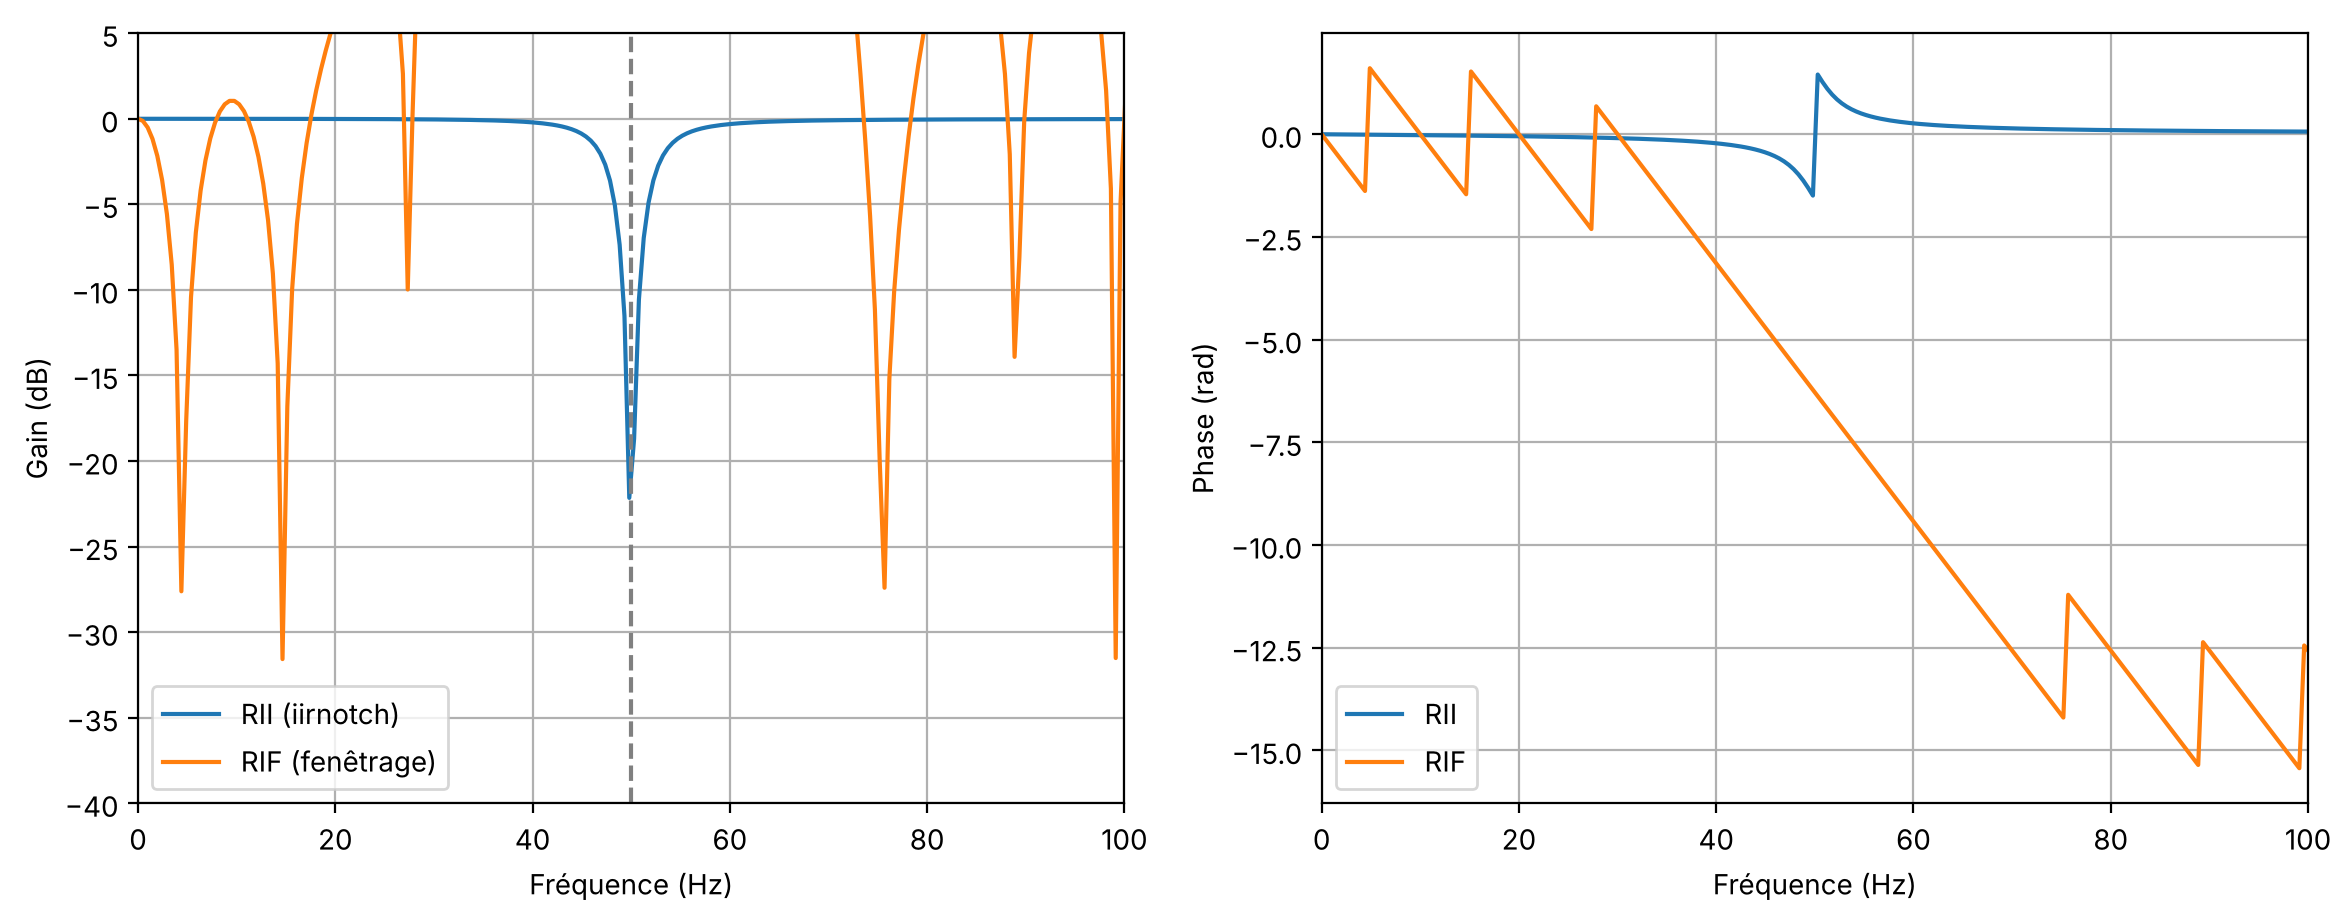

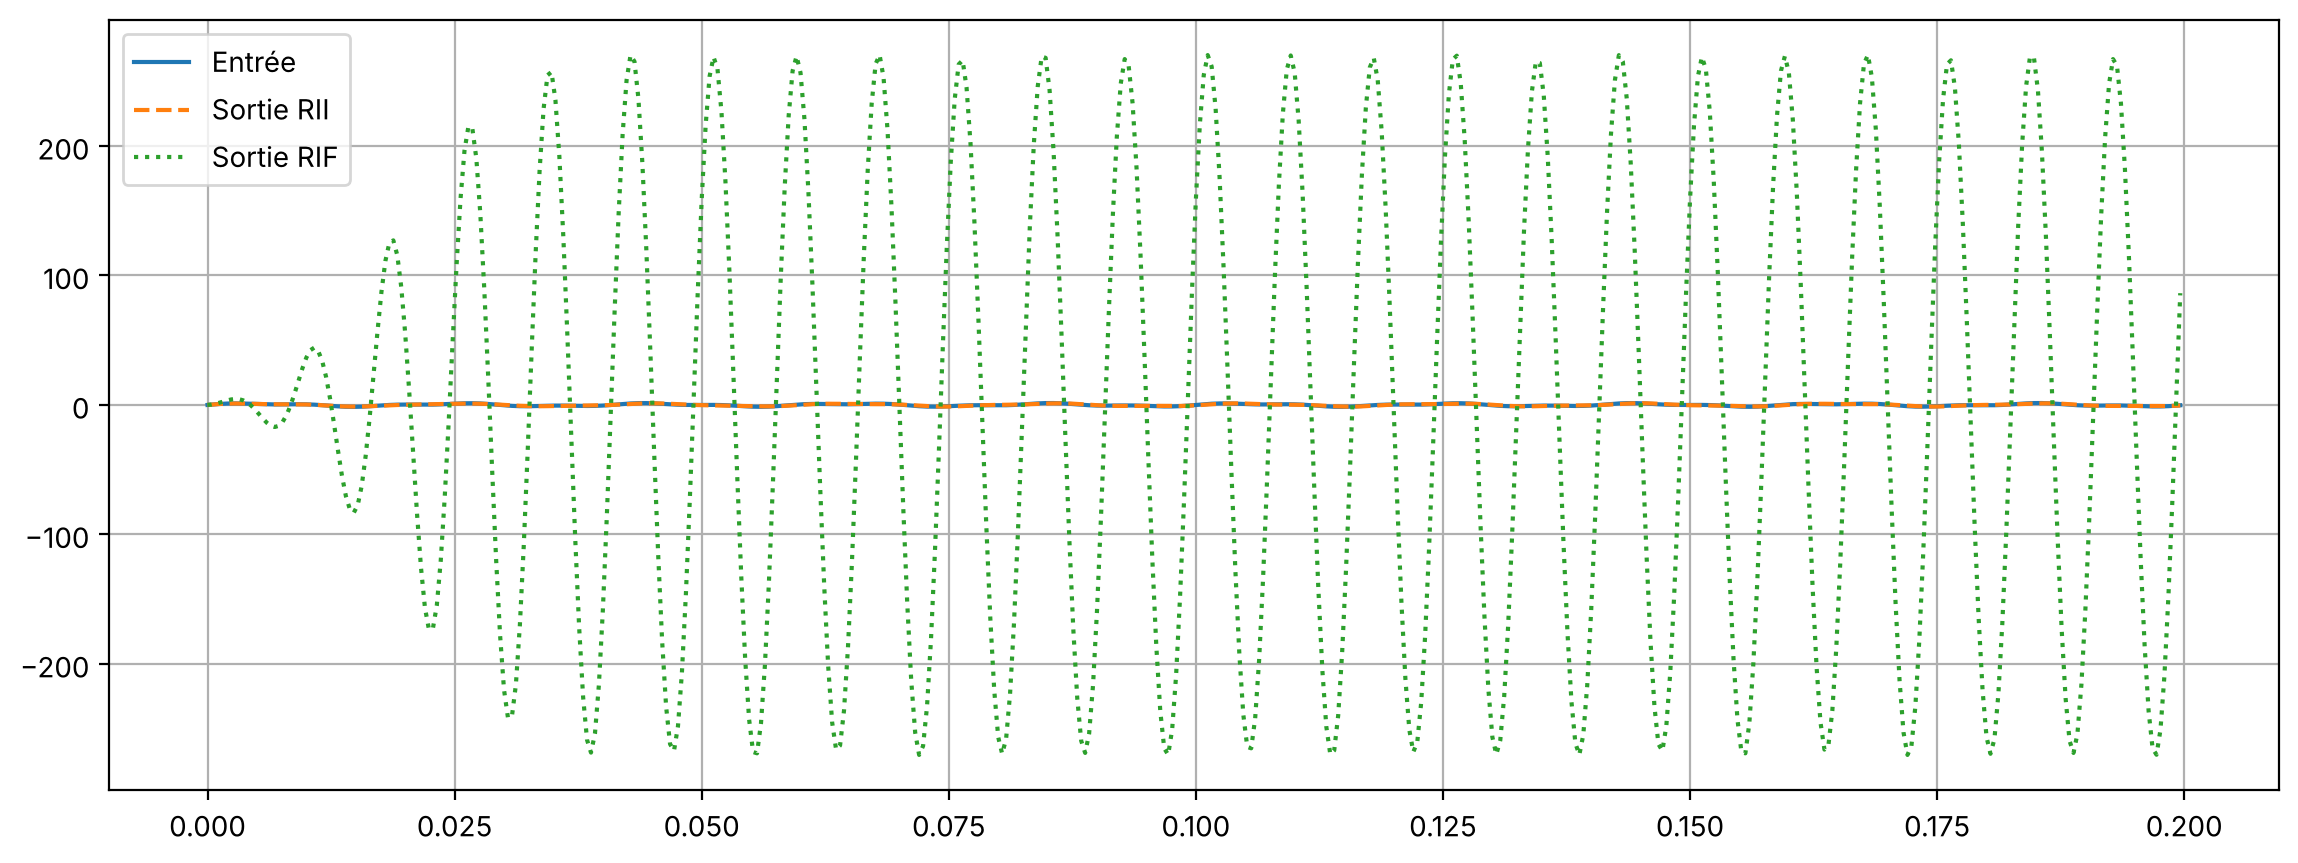

In [7]:
fs = 1000
f0 = 50
Q = 10

# Filtre notch RII (iirnotch)
b_notch, a_notch = signal.iirnotch(f0, Q, fs)

# Filtre notch RIF (fenêtre de Hamming, longueur 101)
N_notch = 101
# Conception par échantillonnage fréquentiel simple
# On va construire un filtre RIF coupe-bande en utilisant la méthode du fenêtrage
# mais pour un notch, on peut utiliser la formule de la réponse impulsionnelle idéale
# d'un coupe-bande : h_ideal[n] = (sin(omega_c2 n) - sin(omega_c1 n))/(pi n)
# avec omega_c1 = 2*pi*(f0 - BW/2)/fs, omega_c2 = 2*pi*(f0 + BW/2)/fs
BW = 10  # Hz
wc1 = 2*np.pi*(f0 - BW/2)/fs
wc2 = 2*np.pi*(f0 + BW/2)/fs
n = np.arange(-(N_notch-1)//2, (N_notch-1)//2 + 1)
h_ideal = np.zeros_like(n, dtype=float)
for i, n_i in enumerate(n):
    if n_i == 0:
        h_ideal[i] = (wc2 - wc1) / np.pi
    else:
        h_ideal[i] = (np.sin(wc2 * n_i) - np.sin(wc1 * n_i)) / (np.pi * n_i)
# Fenêtre de Hamming
window = np.hamming(N_notch)
h_fir = h_ideal * window
h_fir = h_fir / np.sum(h_fir)  # normalisation

# Réponses
w, H_notch_iir = signal.freqz(b_notch, a_notch, worN=1024)
w, H_notch_fir = signal.freqz(h_fir, 1, worN=1024)
freqs = w * fs / (2*np.pi)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(freqs, 20*np.log10(np.abs(H_notch_iir)), label='RII (iirnotch)')
plt.plot(freqs, 20*np.log10(np.abs(H_notch_fir)), label='RIF (fenêtrage)')
plt.axvline(f0, color='gray', linestyle='--')
plt.xlim(0, 100)
plt.ylim(-40, 5)
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Gain (dB)')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(freqs, np.unwrap(np.angle(H_notch_iir)), label='RII')
plt.plot(freqs, np.unwrap(np.angle(H_notch_fir)), label='RIF')
plt.xlim(0, 100)
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Phase (rad)')
plt.legend()
plt.grid()
plt.show()

# Test sur signal
t = np.linspace(0, 0.2, 500, endpoint=False)
x = np.sin(2*np.pi*50*t) + 0.5*np.sin(2*np.pi*120*t)
y_iir = signal.lfilter(b_notch, a_notch, x)
y_fir = signal.lfilter(h_fir, 1, x)

plt.figure(figsize=(14, 5))
plt.plot(t, x, label='Entrée')
plt.plot(t, y_iir, '--', label='Sortie RII')
plt.plot(t, y_fir, ':', label='Sortie RIF')
plt.legend()
plt.grid()
plt.show()

# 4. Exercices – Semaine 10

## Exercice 1 – Implémentation d'un filtre RIF en structure symétrique

Pour un filtre RIF à phase linéaire de longueur impaire, les coefficients sont symétriques. Écrire une fonction `fir_linear_phase(x, b)` qui exploite la symétrie pour réduire le nombre de multiplications de moitié. Tester avec un filtre de longueur 31.

**Code** :

In [8]:
# Exercice 1 — RIF à phase linéaire : on exploite la symétrie b[k] = b[M-1-k]
def fir_linear_phase(x, b):
    # b doit être symétrique et de longueur impaire
    M = len(b)
    if M % 2 == 0:
        raise ValueError("La longueur doit être impaire pour une symétrie simple")
    if not np.allclose(b, b[::-1]):
        raise ValueError("Les coefficients doivent être symétriques")
    x = np.asarray(x, dtype=float)
    N = len(x)
    c = (M - 1) // 2                     # indice du coefficient central
    y = np.zeros(N)
    nb_mult = 0
    for n in range(N):
        # terme central
        acc = b[c] * (x[n - c] if n - c >= 0 else 0.0)
        nb_mult += 1
        # paires symétriques : b[k] * (x[n-k] + x[n-(M-1-k)])  -> 1 seule multiplication par paire
        for k in range(c):
            x1 = x[n - k] if n - k >= 0 else 0.0
            x2 = x[n - (M - 1 - k)] if n - (M - 1 - k) >= 0 else 0.0
            acc += b[k] * (x1 + x2)
            nb_mult += 1
        y[n] = acc
    return y, nb_mult / N

# Test avec un filtre de longueur 31
np.random.seed(0)
b_sym = signal.firwin(31, 0.1)
x_test = np.random.randn(100)
y_sym, mult_par_echantillon = fir_linear_phase(x_test, b_sym)
y_ref = signal.lfilter(b_sym, 1, x_test)

print(f"Erreur max vs lfilter : {np.max(np.abs(y_sym - y_ref)):.2e}")
print(f"Multiplications par échantillon (version symétrique) : {mult_par_echantillon:.0f}")
print(f"Multiplications par échantillon (version directe)    : {len(b_sym)}")

Erreur max vs lfilter : 2.22e-16
Multiplications par échantillon (version symétrique) : 16
Multiplications par échantillon (version directe)    : 31


## Interprétation — Exercice 1

- La symétrie $b[k] = b[M-1-k]$ permet de regrouper les échantillons par paires : $b[k]\,(x[n-k] + x[n-(M-1-k)])$.
- Le nombre de multiplications par échantillon passe de **31 à 16** (soit presque la moitié) ; le nombre d'additions reste à peu près le même.
- Le résultat est identique à `lfilter` (erreur max $\approx 2 \times 10^{-16}$) : on économise du calcul sans changer le filtre.

## Exercice 2 – Filtre RII en cascade vs directe

1. Concevoir un filtre RII elliptique passe-bas avec les spécifications suivantes :
   - Fréquence de coupure 200 Hz, fs=1000 Hz.
   - Atténuation de 60 dB dans la bande stop à partir de 250 Hz.
   - Ondulation en bande passante : 0.5 dB.
2. Obtenir la forme en cascade (sos) et la forme directe.
3. Comparer les réponses en gain et en phase des deux formes.
4. Quantifier les coefficients sur 12 bits et observer l'impact sur la stabilité pour les deux structures.

**Code** :

Ordre elliptique minimal : 7  ->  4 sections d'ordre 2


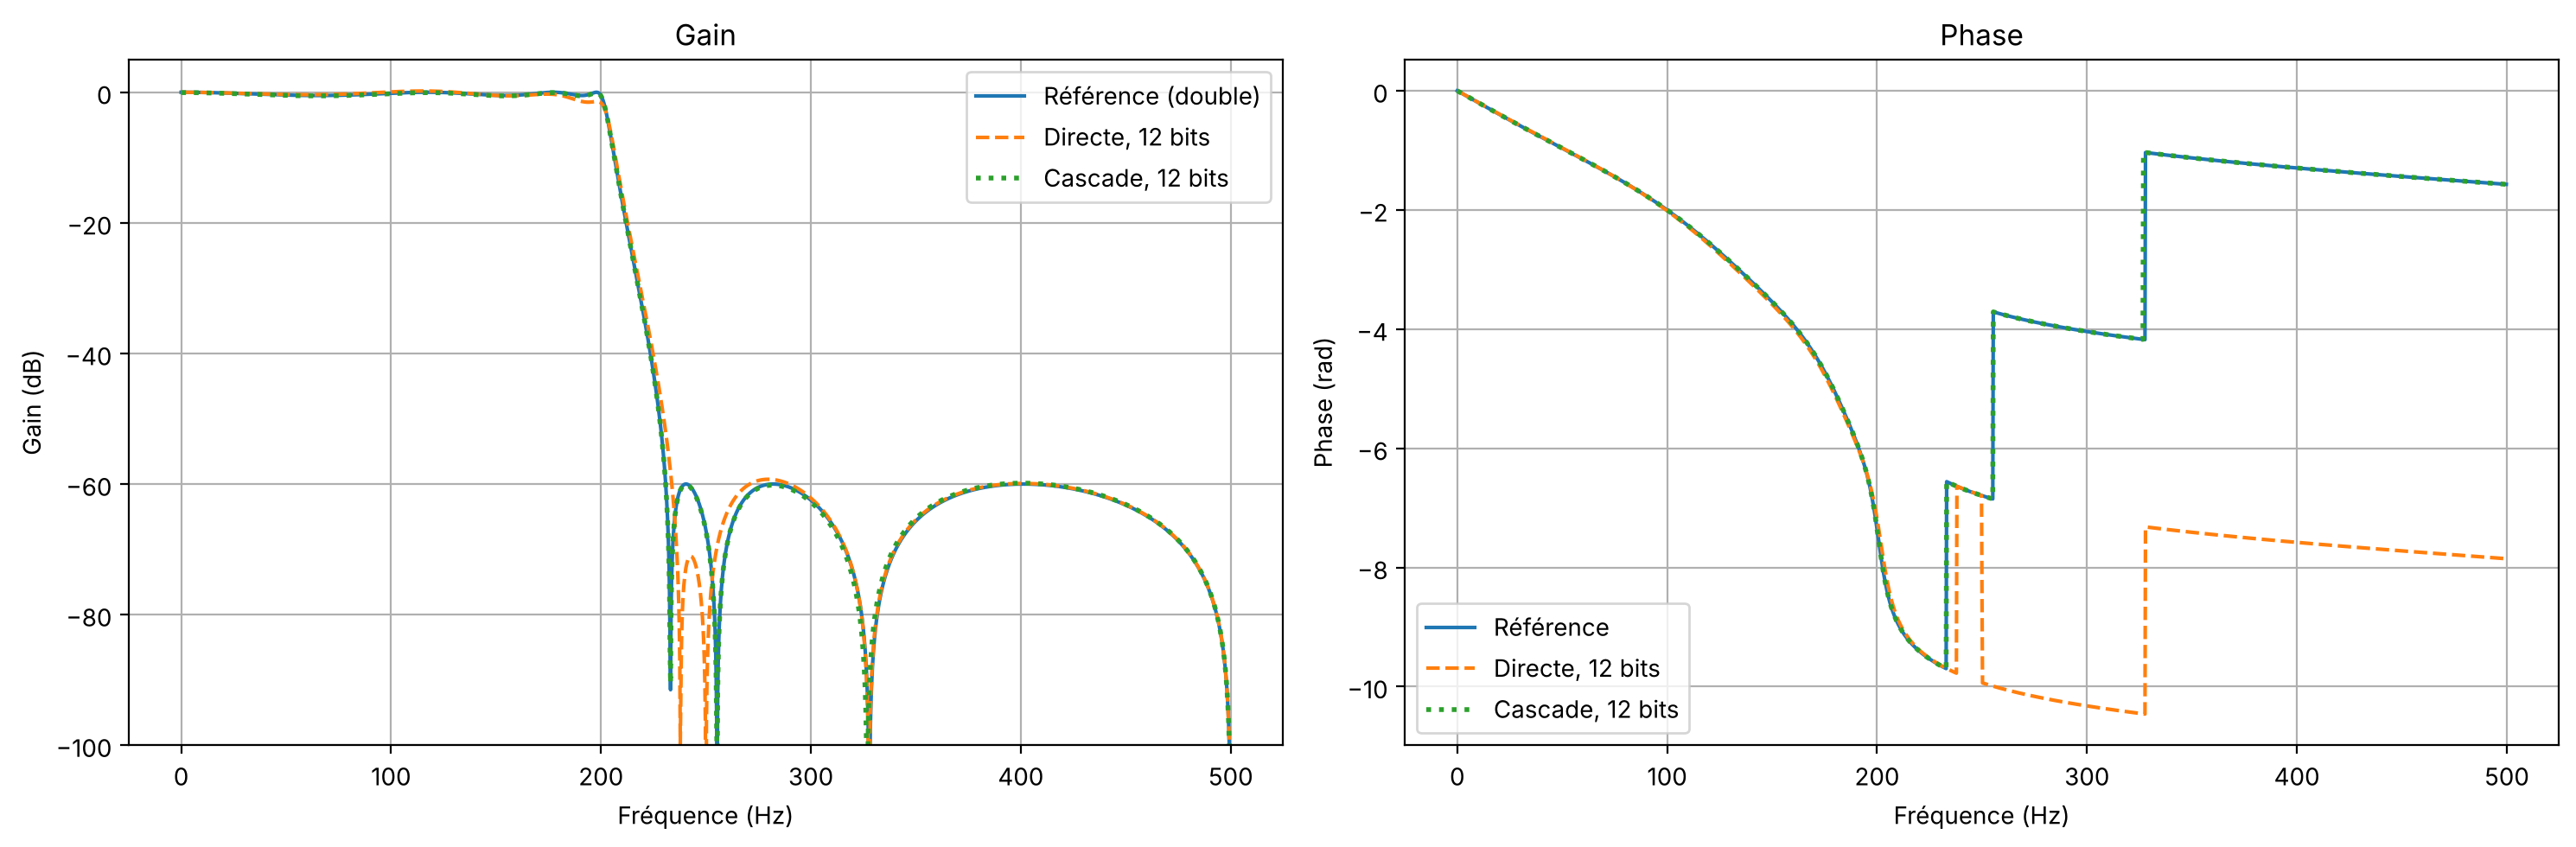

Rayon max des pôles — référence : 0.9710
Rayon max des pôles — directe 12 bits : 0.9685  stable = True
Rayon max des pôles — cascade 12 bits : 0.9710  stable = True
Écart max de gain (dB) — directe : 1.409
Écart max de gain (dB) — cascade : 0.060


In [9]:
# Exercice 2 — Elliptique passe-bas : forme directe vs cascade (SOS) + quantification 12 bits
fs = 1000
fp, fst, rp, rs = 200, 250, 0.5, 60
ordre_e, wn_e = signal.ellipord(fp, fst, rp, rs, fs=fs)
b_e, a_e = signal.ellip(ordre_e, rp, rs, wn_e, btype='low', fs=fs)
sos_e = signal.tf2sos(b_e, a_e)
print(f"Ordre elliptique minimal : {ordre_e}  ->  {len(sos_e)} sections d'ordre 2")

def quantifier(coeffs, n_bits):
    """Quantification en virgule fixe avec mise à l'échelle par une puissance de 2."""
    coeffs = np.asarray(coeffs, dtype=float)
    m = int(np.ceil(np.log2(np.max(np.abs(coeffs)) + 1e-30)))
    m = max(m, 0)
    pas = 2.0**(m - (n_bits - 1))
    return np.round(coeffs / pas) * pas

n_bits = 12
# Forme directe quantifiée
b_dq, a_dq = quantifier(b_e, n_bits), quantifier(a_e, n_bits)
# Forme cascade quantifiée (chaque section quantifiée séparément)
sos_q = np.array([np.concatenate([quantifier(s[:3], n_bits), quantifier(s[3:], n_bits)]) for s in sos_e])

# Réponses en fréquence
w, H0 = signal.freqz(b_e, a_e, worN=2048, fs=fs)
_, Hd = signal.freqz(b_dq, a_dq, worN=2048, fs=fs)
_, Hc = signal.sosfreqz(sos_q, worN=2048, fs=fs)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].plot(w, 20*np.log10(np.abs(H0)+1e-12), label='Référence (double)')
ax[0].plot(w, 20*np.log10(np.abs(Hd)+1e-12), '--', label='Directe, 12 bits')
ax[0].plot(w, 20*np.log10(np.abs(Hc)+1e-12), ':', lw=2, label='Cascade, 12 bits')
ax[0].set_ylim(-100, 5); ax[0].set_xlabel('Fréquence (Hz)'); ax[0].set_ylabel('Gain (dB)')
ax[0].set_title('Gain'); ax[0].legend(); ax[0].grid()
ax[1].plot(w, np.unwrap(np.angle(H0)), label='Référence')
ax[1].plot(w, np.unwrap(np.angle(Hd)), '--', label='Directe, 12 bits')
ax[1].plot(w, np.unwrap(np.angle(Hc)), ':', lw=2, label='Cascade, 12 bits')
ax[1].set_xlabel('Fréquence (Hz)'); ax[1].set_ylabel('Phase (rad)'); ax[1].set_title('Phase')
ax[1].legend(); ax[1].grid()
plt.tight_layout(); plt.show()

# Stabilité : rayon maximal des pôles
r_ref = np.max(np.abs(np.roots(a_e)))
r_dir = np.max(np.abs(np.roots(a_dq)))
r_cas = max(np.max(np.abs(np.roots(s[3:]))) for s in sos_q)
print(f"Rayon max des pôles — référence : {r_ref:.4f}")
print(f"Rayon max des pôles — directe 12 bits : {r_dir:.4f}  stable = {r_dir < 1}")
print(f"Rayon max des pôles — cascade 12 bits : {r_cas:.4f}  stable = {r_cas < 1}")
print(f"Écart max de gain (dB) — directe : {np.max(np.abs(20*np.log10(np.abs(Hd)+1e-12)-20*np.log10(np.abs(H0)+1e-12))[w<200]):.3f}")
print(f"Écart max de gain (dB) — cascade : {np.max(np.abs(20*np.log10(np.abs(Hc)+1e-12)-20*np.log10(np.abs(H0)+1e-12))[w<200]):.3f}")

## Interprétation — Exercice 2

- L'ordre minimal du filtre elliptique est **7**, soit **4 sections** d'ordre 2. Un Butterworth ou un Chebyshev demanderait un ordre bien plus élevé pour le même gabarit.
- À **12 bits**, les deux structures restent **stables** (rayon max des pôles ≈ 0,97), mais la forme directe est moins précise : écart de gain jusqu'à **1,4 dB** en bande passante contre **0,06 dB** pour la cascade.
- La cascade est donc nettement plus robuste, car chaque section d'ordre 2 est quantifiée séparément et ses pôles sont peu perturbés. C'est la structure recommandée en virgule fixe.

## Exercice 3 – Analyse du retard de groupe d'un filtre RIF et RII

1. Concevoir un filtre RIF passe-bas de type window (Hamming) avec fc=150 Hz, fs=1000 Hz, ordre 50.
2. Concevoir un filtre RII Butterworth d'ordre 6 avec les mêmes spécifications.
3. Tracer le retard de groupe des deux filtres sur la bande passante.
4. Commenter la distorsion de phase introduite par chaque filtre.

**Code** :

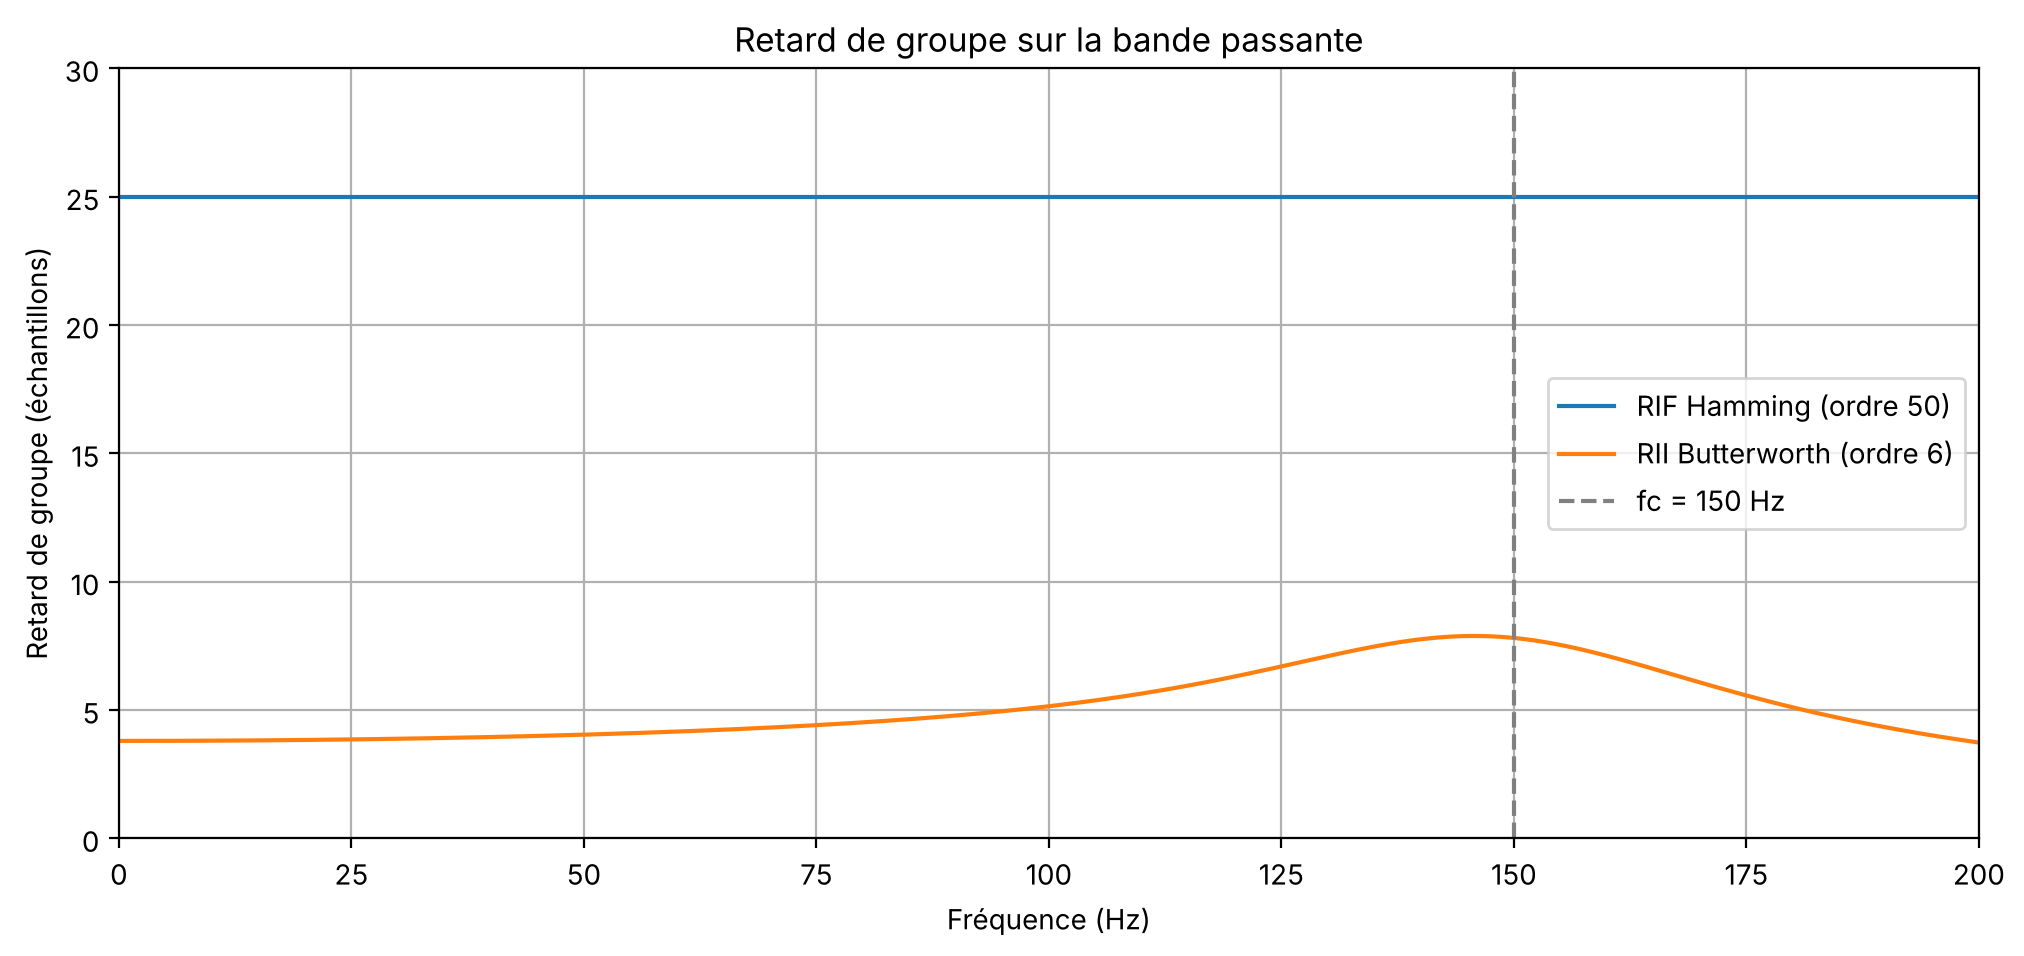

RIF : retard constant = 25.00 échantillons (théorie (N-1)/2 = 25)
RII : retard min = 3.79, max = 7.88 échantillons sur 0-150 Hz
RII : variation du retard = 4.09 échantillons (4.09 ms)


In [10]:
import warnings
warnings.filterwarnings('ignore', category=UserWarning)   # avertissement sans gravité de group_delay à la fréquence de Nyquist
# Exercice 3 — Retard de groupe RIF (Hamming, ordre 50) vs RII (Butterworth, ordre 6)
fs = 1000
fc = 150
b_fir3 = signal.firwin(51, fc, fs=fs, window='hamming')      # ordre 50 -> 51 coefficients
b_iir3, a_iir3 = signal.butter(6, fc, fs=fs, btype='low')

w_g, gd_f = signal.group_delay((b_fir3, 1), w=2048, fs=fs)
_, gd_i = signal.group_delay((b_iir3, a_iir3), w=2048, fs=fs)

plt.figure(figsize=(12, 5))
plt.plot(w_g, gd_f, label='RIF Hamming (ordre 50)')
plt.plot(w_g, gd_i, label='RII Butterworth (ordre 6)')
plt.axvline(fc, color='gray', ls='--', label='fc = 150 Hz')
plt.xlim(0, 200); plt.ylim(0, 30)
plt.xlabel('Fréquence (Hz)'); plt.ylabel('Retard de groupe (échantillons)')
plt.title('Retard de groupe sur la bande passante'); plt.legend(); plt.grid(); plt.show()

bp = w_g <= fc
print(f"RIF : retard constant = {gd_f[bp].mean():.2f} échantillons (théorie (N-1)/2 = 25)")
print(f"RII : retard min = {gd_i[bp].min():.2f}, max = {gd_i[bp].max():.2f} échantillons sur 0-{fc} Hz")
print(f"RII : variation du retard = {gd_i[bp].max()-gd_i[bp].min():.2f} échantillons ({(gd_i[bp].max()-gd_i[bp].min())/fs*1000:.2f} ms)")

## Interprétation — Exercice 3

- **RIF** (Hamming, ordre 50) : retard de groupe **constant = 25 échantillons** = $(N-1)/2$. Tous les composants du signal sont retardés pareil, donc **pas de distorsion de phase**, mais le retard est élevé.
- **RII** (Butterworth, ordre 6) : retard plus faible (**3,8 à 7,9 échantillons**) mais **variable** : il varie d'environ **4 échantillons** sur la bande passante et augmente vers la coupure. Les composantes ne sont pas retardées de la même façon, ce qui **déforme** la forme d'onde.
- Choix : RIF si la fidélité de forme compte (audio, ECG), RII si le retard et le coût de calcul comptent.

## Exercice 4 – Effet du nombre de bits sur la réponse d'un filtre RII

Pour un filtre RII passe-bande (Butterworth ordre 4, bande 100-200 Hz, fs=1000 Hz) :
1. Quantifier les coefficients avec différentes résolutions (8, 10, 12, 16 bits).
2. Pour chaque résolution, tracer la réponse en gain et repérer les dégradations.
3. Observer le déplacement des pôles et déterminer la résolution minimale pour garantir la stabilité.

**Code** :

Référence : rayon max des pôles = 0.91508
 8 bits : rayon max des pôles = 1.19451  ->  stable = False
10 bits : rayon max des pôles = 1.00964  ->  stable = False
12 bits : rayon max des pôles = 0.90622  ->  stable = True
16 bits : rayon max des pôles = 0.91471  ->  stable = True


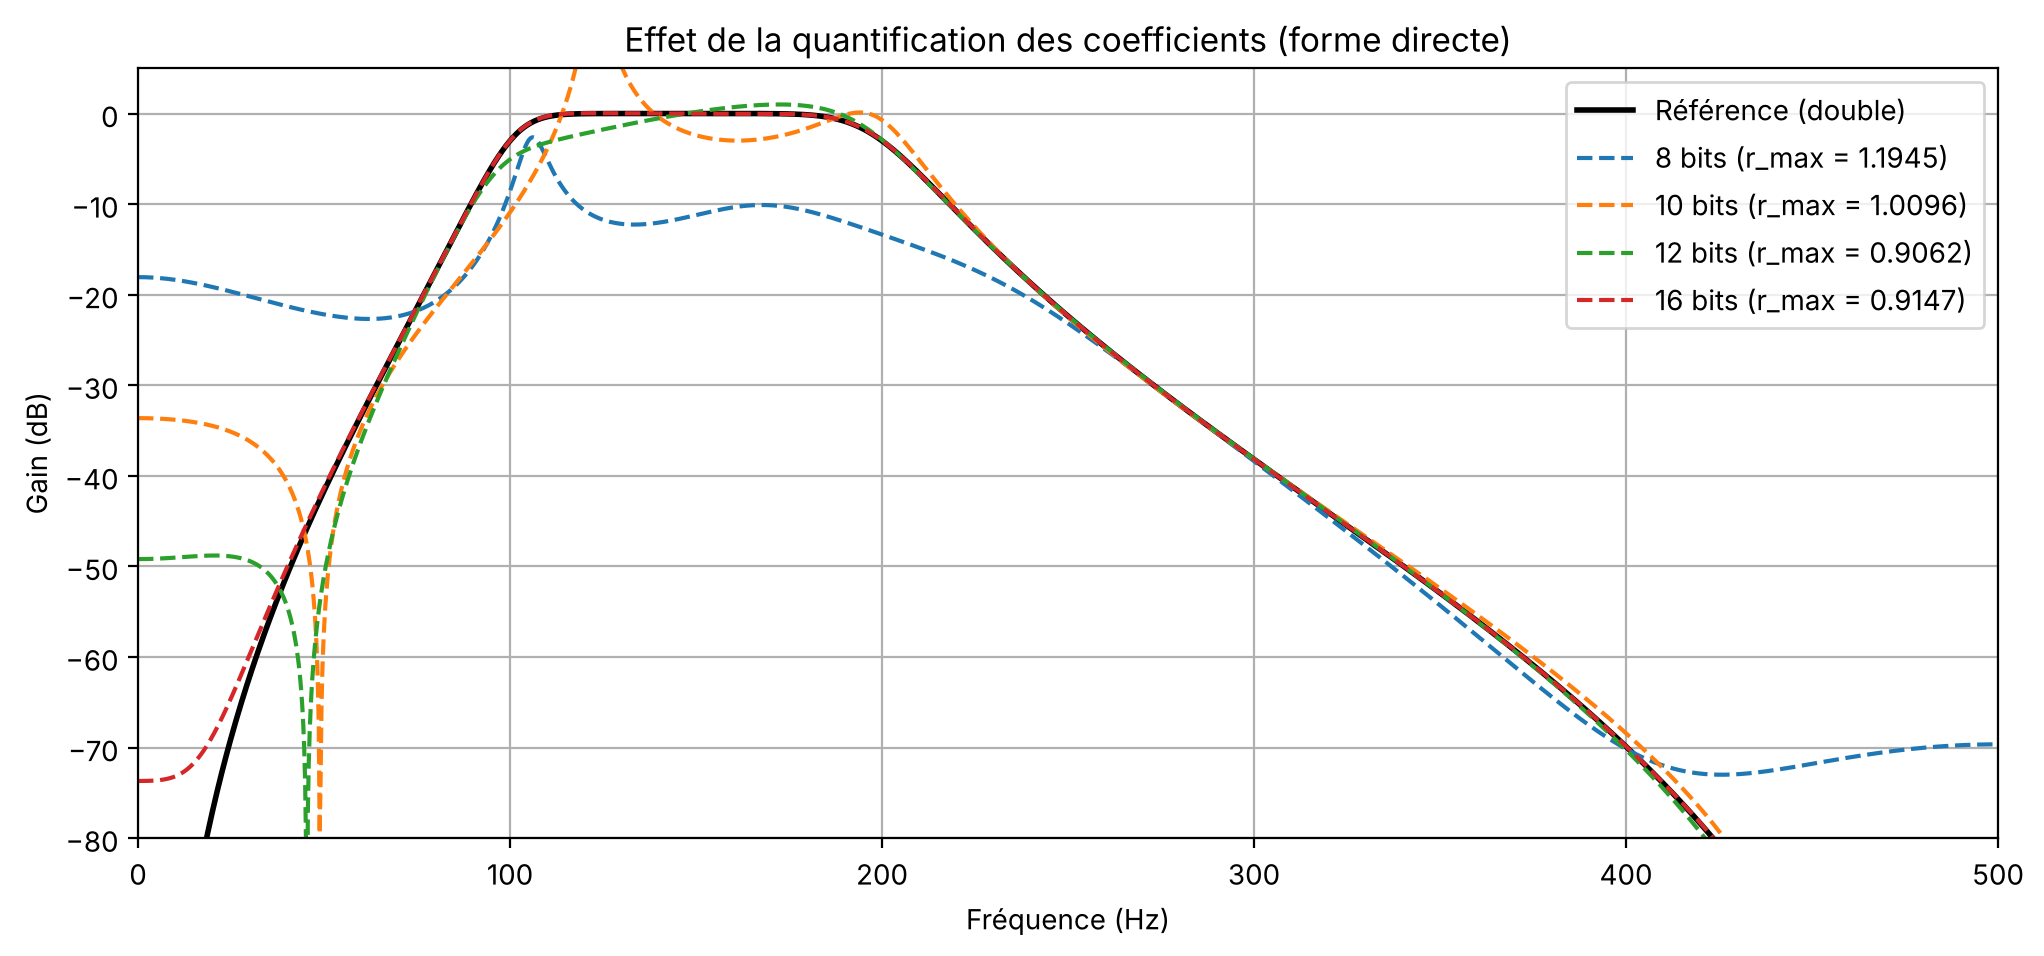

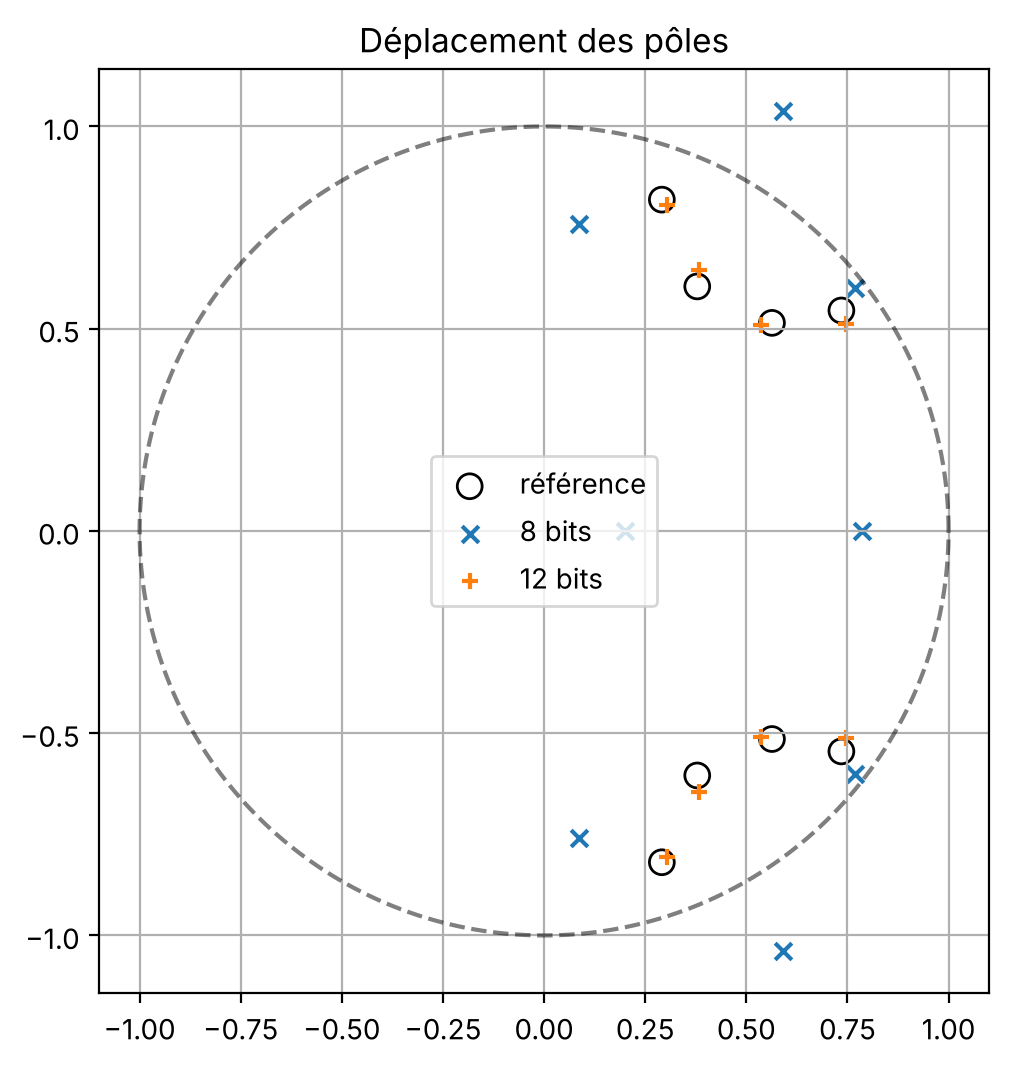

In [11]:
# Exercice 4 — Butterworth passe-bande ordre 4 (100-200 Hz) : effet du nombre de bits
fs = 1000
b_pb, a_pb = signal.butter(4, [100, 200], btype='bandpass', fs=fs)
w, H_ref = signal.freqz(b_pb, a_pb, worN=2048, fs=fs)

plt.figure(figsize=(12, 5))
plt.plot(w, 20*np.log10(np.abs(H_ref)+1e-12), 'k', lw=2, label='Référence (double)')
print(f"Référence : rayon max des pôles = {np.max(np.abs(np.roots(a_pb))):.5f}")
for n_bits in [8, 10, 12, 16]:
    b_q = quantifier(b_pb, n_bits)
    a_q = quantifier(a_pb, n_bits)
    r = np.max(np.abs(np.roots(a_q)))
    _, H_q = signal.freqz(b_q, a_q, worN=2048, fs=fs)
    plt.plot(w, 20*np.log10(np.abs(H_q)+1e-12), '--', label=f'{n_bits} bits (r_max = {r:.4f})')
    print(f"{n_bits:2d} bits : rayon max des pôles = {r:.5f}  ->  stable = {r < 1}")
plt.ylim(-80, 5); plt.xlim(0, 500)
plt.xlabel('Fréquence (Hz)'); plt.ylabel('Gain (dB)')
plt.title('Effet de la quantification des coefficients (forme directe)')
plt.legend(); plt.grid(); plt.show()

# Déplacement des pôles
theta = np.linspace(0, 2*np.pi, 300)
plt.figure(figsize=(6, 6))
plt.plot(np.cos(theta), np.sin(theta), 'k--', alpha=0.5)
p0 = np.roots(a_pb); plt.scatter(p0.real, p0.imag, marker='o', s=80, facecolors='none', edgecolors='k', label='référence')
for n_bits, m in [(8, 'x'), (12, '+')]:
    p = np.roots(quantifier(a_pb, n_bits)); plt.scatter(p.real, p.imag, marker=m, label=f'{n_bits} bits')
plt.gca().set_aspect('equal'); plt.title('Déplacement des pôles'); plt.legend(); plt.grid(); plt.show()

## Interprétation — Exercice 4

| Résolution | Rayon max des pôles | Stable ? |
|---|---|---|
| 8 bits | 1,195 | non |
| 10 bits | 1,010 | non |
| 12 bits | 0,906 | oui |
| 16 bits | 0,915 | oui |
| référence (double) | 0,915 | oui |

- À 8 et 10 bits, la quantification des coefficients du dénominateur déplace des pôles **hors du cercle unité** : le filtre devient instable.
- Dans cet essai, la résolution minimale qui garantit la stabilité est donc **12 bits** pour la forme directe.
- Un passe-bande d'ordre 8 en forme directe est très sensible aux coefficients ; la forme **en cascade de sections d'ordre 2** serait bien plus robuste avec moins de bits.

## Exercice 5 – Mise en œuvre d'un filtre adaptatif simple (LMS) – Introduction

Un filtre adaptatif permet d'ajuster ses coefficients pour minimiser une erreur. Implémenter un filtre RIF adaptatif utilisant l'algorithme LMS (Least Mean Squares) pour annuler un écho. On donne un signal désiré $d[n]$ et un signal d'entrée $x[n]$ corrélé avec l'écho.

1. Générer un signal $x[n]$ aléatoire.
2. Créer un signal écho : $y[n] = 0.8 x[n-10] + bruit$.
3. Utiliser un filtre RIF de longueur 20 pour estimer la réponse de l'écho.
4. Appliquer l'algorithme LMS (pas = 0.01) pour mettre à jour les coefficients.
5. Afficher l'erreur en fonction des itérations et les coefficients convergés.

**Code** :

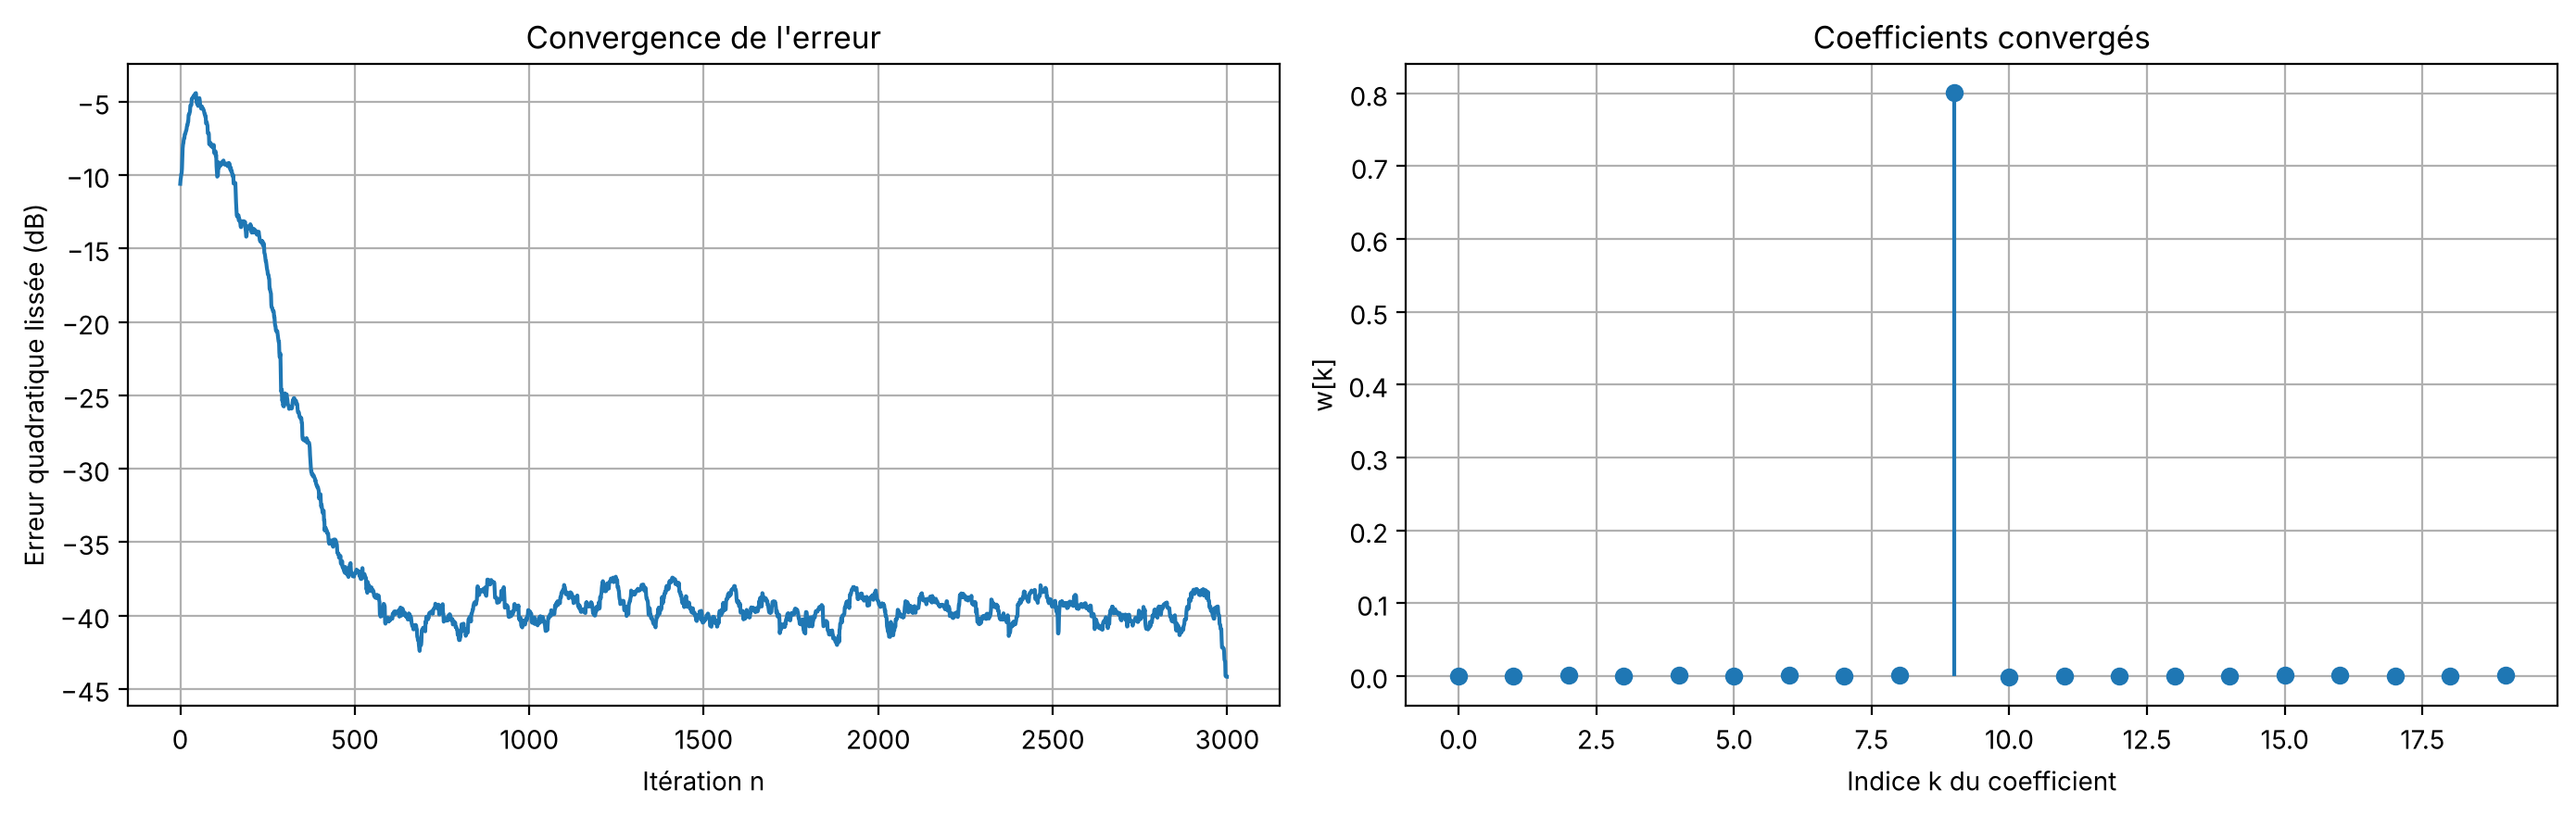

Coefficient dominant : w[9] = 0.801  (cible : 0.8 au retard 10, soit indice 9)
Erreur quadratique moyenne sur les 500 premières itérations : 0.0736
Erreur quadratique moyenne sur les 500 dernières itérations : 0.000106


In [12]:
# Exercice 5 — Filtre adaptatif LMS : annulation d'écho
def lms_filter(x, d, M, mu):
    N = len(x)
    w = np.zeros(M)
    y = np.zeros(N)
    e = np.zeros(N)
    for n in range(M, N):
        x_n = x[n-M:n][::-1]  # x[n-1], x[n-2], ..., x[n-M]
        y[n] = np.dot(w, x_n)
        e[n] = d[n] - y[n]
        w = w + mu * e[n] * x_n
    return y, e, w

np.random.seed(1)
N = 3000
x = np.random.randn(N)
D, alpha = 10, 0.8
d = np.zeros(N)
d[D:] = alpha * x[:-D]                 # écho : 0.8 x[n-10]
d += 0.01 * np.random.randn(N)         # bruit
mu, M = 0.01, 20
y, e, w = lms_filter(x, d, M, mu)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(10*np.log10(np.convolve(e**2, np.ones(50)/50, mode='same') + 1e-12))
ax[0].set_xlabel('Itération n'); ax[0].set_ylabel("Erreur quadratique lissée (dB)")
ax[0].set_title("Convergence de l'erreur"); ax[0].grid()
ax[1].stem(np.arange(M), w, basefmt=' ')
ax[1].set_xlabel('Indice k du coefficient'); ax[1].set_ylabel('w[k]')
ax[1].set_title('Coefficients convergés'); ax[1].grid()
plt.tight_layout(); plt.show()

k_max = np.argmax(np.abs(w))
print(f"Coefficient dominant : w[{k_max}] = {w[k_max]:.3f}  (cible : 0.8 au retard {D}, soit indice {D-1})")
print(f"Erreur quadratique moyenne sur les 500 premières itérations : {np.mean(e[M:500]**2):.4f}")
print(f"Erreur quadratique moyenne sur les 500 dernières itérations : {np.mean(e[-500:]**2):.6f}")

## Interprétation — Exercice 5

- Le coefficient dominant converge vers **$w[9] \approx 0{,}80$** : c'est bien l'écho $0{,}8\,x[n-10]$ (le retard de 10 échantillons correspond à l'indice 9 car $x_n$ commence à $x[n-1]$). Les autres coefficients restent proches de 0.
- L'erreur quadratique moyenne passe de **0,074** au début à **$1{,}1 \times 10^{-4}$** à la fin, ce qui correspond à la **variance du bruit** ajouté ($0{,}01^2 = 10^{-4}$) : l'écho est annulé, il ne reste que le bruit.
- Le pas $\mu$ règle un compromis : trop petit, la convergence est lente ; trop grand, l'algorithme oscille ou diverge. Ici $\mu = 0{,}01$ converge en quelques centaines d'itérations.

# 5. Livrable Semaine 10

- Remplir les cellules de code avec vos solutions.
- Répondre aux questions théoriques dans les cellules markdown.
- Inclure des commentaires explicatifs.
- Rendre le notebook complet (cellules exécutées).

**Date de rendu** : à définir par l'enseignant.

---